# DinoBloom embeddings — CP-CML granulocytic maturation

## Step 0. Read-only crop integrity audit (46 CP-CML patients)

1. cohort selection from the consensus ANN DICOMs
2. DICOM counts, with repeated `AnnotationGroupSequence` labels **summed**
3. DICOM vs `metadata.csv` vs PNG counts (patient/label, patient, global)
4. file-level checks (missing, orphan, duplicate, unexpected)
5. coordinate-level matching between DICOM and metadata
6. PNG header checks
7. pixel-spacing / low-resolution patients
8. five-stage recount

In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import pydicom
from PIL import Image

DATA_DIR = Path("../data")
ANNOTATION_DIR = DATA_DIR / "annotations" / "bonemarrowwsi_pediatricleukemia"
WSI_DIR = DATA_DIR / "wsi"
CROP_DIR = DATA_DIR / "crops"

TARGET_STAGES = [
    "promyelocyte",
    "neutrophilic_myelocyte",
    "neutrophilic_metamyelocyte",
    "neutrophilic_band",
    "segmented_neutrophil",
]

pd.set_option("display.width", 200)

### 0.1 Cohort selection from consensus ANN DICOMs

In [2]:
ann_paths = sorted(ANNOTATION_DIR.rglob("*.dcm"))
all_ann = [(p, pydicom.dcmread(p)) for p in ann_paths]
print("ANN DICOM files found:", len(all_ann))

diagnosis_all = pd.Series(
    [str(ds.get("AdmittingDiagnosesDescription", "MISSING")) for _, ds in all_ann]
)
print("\nDiagnoses (all ANN files):")
print(diagnosis_all.value_counts().to_string())

cml = [
    (p, ds) for p, ds in all_ann
    if "Chronic Phase Chronic Myeloid Leukemia"
    in str(ds.get("AdmittingDiagnosesDescription", ""))
]

print("\nCP-CML ANN files:", len(cml))
print("Exact diagnosis strings in cohort:",
      sorted({str(ds.AdmittingDiagnosesDescription) for _, ds in cml}))
print("Modality:", Counter(str(ds.Modality) for _, ds in cml))
print("SeriesDescription:", Counter(str(ds.get("SeriesDescription", "")) for _, ds in cml))

files_per_patient = Counter(str(ds.PatientID) for _, ds in cml)
print("Unique patients:", len(files_per_patient))
print("Patients with != 1 ANN file:", {k: v for k, v in files_per_patient.items() if v != 1})

ann_by_patient = {str(ds.PatientID): ds for _, ds in cml}

crop_patients = {d.name for d in CROP_DIR.iterdir() if d.is_dir()}
print("\nCrop patient folders:", len(crop_patients))
print("Cohort patients without crop folder:", sorted(set(ann_by_patient) - crop_patients))
print("Crop folders not in cohort:", sorted(crop_patients - set(ann_by_patient)))

ANN DICOM files found: 113

Diagnoses (all ANN files):
Chronic Phase Chronic Myeloid Leukemia, BCR-ABL1 Positive           46
B Acute Lymphoblastic Leukemia                                      32
Mixed Phenotype Acute Leukemia, B/Myeloid                            6
Acute Monocytic Leukemia                                             5
Acute Myeloid Leukemia with Maturation                               5
T Acute Lymphoblastic Leukemia                                       5
Blast Phase Chronic Myeloid Leukemia, BCR-ABL1 Positive              4
MISSING                                                              3
Acute Promyelocytic Leukemia with t(15;17)(q24.1;q21.2);PML-RARA     3
Acute Myelomonocytic Leukemia                                        3
Acute Myeloid Leukemia without Maturation                            1

CP-CML ANN files: 46
Exact diagnosis strings in cohort: ['Chronic Phase Chronic Myeloid Leukemia, BCR-ABL1 Positive']
Modality: Counter({'ANN': 46})
SeriesDescript

### 0.2 DICOM annotations (repeated label groups are summed)

In [3]:
group_rows = []
dicom_rows = []

for pid, ds in sorted(ann_by_patient.items()):
    for group_index, group in enumerate(ds.AnnotationGroupSequence):
        label = str(group.AnnotationGroupLabel)
        n = int(group.NumberOfAnnotations)

        has_coords = "PointCoordinatesData" in group
        points = (
            np.frombuffer(group.PointCoordinatesData, dtype="<f4")
            if has_coords else np.array([])
        )

        group_rows.append({
            "patient_id": pid,
            "group_index": group_index,
            "label": label,
            "n": n,
            "graphic_type": str(group.get("GraphicType", "MISSING")),
            "has_point_coords": has_coords,
            "length_ok": len(points) == n * 8,
        })

        if len(points) != n * 8:
            continue

        for j, rect in enumerate(points.reshape(n, 4, 2)):
            dicom_rows.append({
                "patient_id": pid,
                "label": label,
                "group_index": group_index,
                "index_in_group": j,
                "bbox_x_min": float(rect[:, 0].min()),
                "bbox_y_min": float(rect[:, 1].min()),
                "bbox_x_max": float(rect[:, 0].max()),
                "bbox_y_max": float(rect[:, 1].max()),
            })

groups = pd.DataFrame(group_rows)
dicom = pd.DataFrame(dicom_rows)

print("Annotation groups:", len(groups))
print("GraphicType:", groups["graphic_type"].value_counts().to_dict())
print("AnnotationCoordinateType:",
      Counter(str(ds.get("AnnotationCoordinateType", "MISSING")) for ds in ann_by_patient.values()))
print("Groups missing PointCoordinatesData:", (~groups["has_point_coords"]).sum())
print("Groups with coordinate length != n*8:", (~groups["length_ok"]).sum())

print("\nSum of NumberOfAnnotations:", groups["n"].sum())
print("Decoded rectangles:         ", len(dicom))

# Accumulated (not overwritten) per patient/label
dicom_label_counts = groups.groupby(["patient_id", "label"])["n"].sum()

repeated = (
    groups.groupby(["patient_id", "label"])["n"]
    .agg(n_groups="size", group_sizes=list, total="sum")
    .query("n_groups > 1")
)
print("\nPatient/label combinations with repeated groups:", len(repeated))
print("Repeated labels:", repeated.reset_index()["label"].value_counts().to_dict())
print(repeated.to_string())

Annotation groups: 1346
GraphicType: {'RECTANGLE': 1346}
AnnotationCoordinateType: Counter({'2D': 46})
Groups missing PointCoordinatesData: 0
Groups with coordinate length != n*8: 0

Sum of NumberOfAnnotations: 15288
Decoded rectangles:          15288

Patient/label combinations with repeated groups: 37
Repeated labels: {'technically_unfit': 15, 'no_consensus_found': 8, 'artifact': 5, 'thrombocyte_aggregate': 3, 'megakaryocyte': 2, 'phagocytosis': 1, 'thrombocyte': 1, 'damaged_cell': 1, 'pseudo_gaucher_cell': 1}
                                                        n_groups group_sizes  total
patient_id                       label                                             
02E74F10E0327AD868D138F2B4FDD6F0 artifact                      2     [13, 1]     14
                                 no_consensus_found            2      [2, 1]      3
                                 technically_unfit             2      [5, 1]      6
1F0E3DAD99908345F7439F8FFABDFFC4 no_consensus_found           

### 0.3 Load metadata.csv and inventory every file in the crop folders

In [4]:
EXPECTED_COLUMNS = [
    "annotation_index", "label",
    "bbox_x_min", "bbox_y_min", "bbox_x_max", "bbox_y_max",
    "bbox_width", "bbox_height",
    "patient_id", "center_x", "center_y",
    "crop_x", "crop_y", "crop_size", "filename",
]

meta_frames = []
schema_problems = {}
png_rows = []
unexpected = []

for pid in sorted(ann_by_patient):
    patient_dir = CROP_DIR / pid
    metadata_path = patient_dir / "metadata.csv"

    if not metadata_path.exists():
        unexpected.append((pid, "MISSING metadata.csv"))
        continue

    m = pd.read_csv(metadata_path)
    if list(m.columns) != EXPECTED_COLUMNS:
        schema_problems[pid] = list(m.columns)
    m["folder_patient_id"] = pid
    meta_frames.append(m)

    for entry in patient_dir.iterdir():
        if entry.name in (".DS_Store", "metadata.csv"):
            continue
        if not entry.is_dir():
            unexpected.append((pid, f"file at patient level: {entry.name}"))
            continue
        for f in entry.iterdir():
            if f.name == ".DS_Store":
                continue
            if f.is_file() and f.suffix == ".png":
                png_rows.append({
                    "patient_id": pid,
                    "folder_label": entry.name,
                    "basename": f.name,
                    "path": f,
                })
            else:
                unexpected.append((pid, f"non-PNG entry: {entry.name}/{f.name}"))

meta = pd.concat(meta_frames, ignore_index=True)
pngs = pd.DataFrame(png_rows)

print("metadata.csv files read:", len(meta_frames))
print("Schema matches expected 15 columns for all:", not schema_problems, schema_problems or "")
print("Metadata rows:", len(meta))
print("PNG files:", len(pngs))
print("metadata patient_id != folder name:",
      (meta["patient_id"].astype(str) != meta["folder_patient_id"]).sum())
print("Null values per column:", meta[EXPECTED_COLUMNS].isna().sum()[lambda s: s > 0].to_dict())
print("Unexpected entries:", len(unexpected))
for u in unexpected[:20]:
    print("  ", u)

metadata.csv files read: 46
Schema matches expected 15 columns for all: True 
Metadata rows: 15288
PNG files: 15288
metadata patient_id != folder name: 0
Null values per column: {}
Unexpected entries: 0


### 0.4 Count comparison: DICOM vs metadata vs PNG

In [5]:
meta_label_counts = meta.groupby(["folder_patient_id", "label"]).size()
meta_label_counts.index.names = ["patient_id", "label"]

png_label_counts = pngs.groupby(["patient_id", "folder_label"]).size()
png_label_counts.index.names = ["patient_id", "label"]

counts = pd.concat(
    {"dicom": dicom_label_counts, "metadata": meta_label_counts, "png": png_label_counts},
    axis=1,
).fillna(0).astype(int)

counts["match"] = (counts["dicom"] == counts["metadata"]) & (counts["dicom"] == counts["png"])

print("Patients:", counts.index.get_level_values("patient_id").nunique())
print("Patient/label combinations:", len(counts))
print("Mismatched patient/label combinations:", (~counts["match"]).sum())
if (~counts["match"]).any():
    print(counts[~counts["match"]].to_string())

patient_counts = counts.groupby("patient_id")[["dicom", "metadata", "png"]].sum()
patient_counts["match"] = (
    (patient_counts["dicom"] == patient_counts["metadata"])
    & (patient_counts["dicom"] == patient_counts["png"])
)
print("\nPatients with matching totals:", patient_counts["match"].sum(), "/", len(patient_counts))
if (~patient_counts["match"]).any():
    print(patient_counts[~patient_counts["match"]].to_string())

print("\nGLOBAL TOTALS")
print("DICOM annotations:", counts["dicom"].sum())
print("Metadata rows:    ", counts["metadata"].sum())
print("PNG files:        ", counts["png"].sum())

Patients: 46
Patient/label combinations: 1309
Mismatched patient/label combinations: 0

Patients with matching totals: 46 / 46

GLOBAL TOTALS
DICOM annotations: 15288
Metadata rows:     15288
PNG files:         15288


### 0.5 File-level checks

In [6]:
meta["basename"] = meta["filename"].map(lambda s: Path(s).name)
meta["stored_root"] = meta["filename"].map(lambda s: str(Path(s).parents[2]))
meta["resolved_path"] = [
    CROP_DIR / pid / label / name
    for pid, label, name in zip(meta["folder_patient_id"], meta["label"], meta["basename"])
]

print("Stored filename roots (path prefix in metadata 'filename'):")
print(meta.groupby("stored_root")["folder_patient_id"].agg(["size", "nunique"]).to_string())
print("Stored 'filename' that exists as written (relative to notebooks/):",
      meta["filename"].map(lambda s: Path(s).exists()).sum(), "/", len(meta))

print("\nDuplicate full 'filename' values:", meta["filename"].duplicated().sum())
print("Duplicate (patient, basename):", meta.duplicated(["folder_patient_id", "basename"]).sum())
print("Duplicate (patient, annotation_index):", meta.duplicated(["folder_patient_id", "annotation_index"]).sum())

# Filename convention: {pid}_{idx:04d}_{label}.png ; folder = label
expected_name = [
    f"{pid}_{int(i):04d}_{label}.png"
    for pid, i, label in zip(meta["folder_patient_id"], meta["annotation_index"], meta["label"])
]
print("Basename != {pid}_{annotation_index:04d}_{label}.png:",
      (meta["basename"] != pd.Series(expected_name)).sum())
print("Folder in stored path != label column:",
      (meta["filename"].map(lambda s: Path(s).parent.name) != meta["label"]).sum())

missing = meta[~meta["resolved_path"].map(Path.exists)]
print("\nMetadata rows whose crops/<pid>/<label>/<basename> is MISSING:", len(missing))

meta_keys = Counter(zip(meta["folder_patient_id"], meta["label"], meta["basename"]))
png_keys = Counter(zip(pngs["patient_id"], pngs["folder_label"], pngs["basename"]))

orphans = [k for k in png_keys if k not in meta_keys]
multi_ref = {k: v for k, v in meta_keys.items() if v > 1}
print("Orphan PNGs (not in any metadata row):", len(orphans))
print("PNGs referenced by >1 metadata row:", len(multi_ref))

# Label folders not present in the DICOM for that patient; empty label folders
dicom_labels = groups.groupby("patient_id")["label"].agg(set)
extra_folders = [
    (pid, d.name)
    for pid in ann_by_patient
    for d in (CROP_DIR / pid).iterdir()
    if d.is_dir() and d.name not in dicom_labels[pid]
]
empty_folders = [
    (pid, d.name)
    for pid in ann_by_patient
    for d in (CROP_DIR / pid).iterdir()
    if d.is_dir() and not any(d.glob("*.png"))
]
print("Label folders not in that patient's DICOM:", extra_folders)
print("Empty label folders:", empty_folders)

Stored filename roots (path prefix in metadata 'filename'):
                      size  nunique
stored_root                        
../data/cell_crops)   1412        2
../data/crops        13876       44
Stored 'filename' that exists as written (relative to notebooks/): 13876 / 15288

Duplicate full 'filename' values: 0
Duplicate (patient, basename): 0
Duplicate (patient, annotation_index): 1125
Basename != {pid}_{annotation_index:04d}_{label}.png: 0
Folder in stored path != label column: 0

Metadata rows whose crops/<pid>/<label>/<basename> is MISSING: 0
Orphan PNGs (not in any metadata row): 0
PNGs referenced by >1 metadata row: 0
Label folders not in that patient's DICOM: []
Empty label folders: []


### 0.6 Coordinate-level matching and duplicate boxes

In [7]:
BOX = ["bbox_x_min", "bbox_y_min", "bbox_x_max", "bbox_y_max"]

dicom_keys = Counter(
    (r.patient_id, r.label, r.bbox_x_min, r.bbox_y_min, r.bbox_x_max, r.bbox_y_max)
    for r in dicom.itertuples()
)
meta_box_keys = Counter(
    (r.folder_patient_id, r.label, float(r.bbox_x_min), float(r.bbox_y_min),
     float(r.bbox_x_max), float(r.bbox_y_max))
    for r in meta.itertuples()
)

print("DICOM boxes not matched by metadata:", sum((dicom_keys - meta_box_keys).values()))
print("Metadata boxes not matched by DICOM:", sum((meta_box_keys - dicom_keys).values()))

# bbox_width/height and center consistency inside metadata
print("bbox_width != x_max - x_min:",
      (~np.isclose(meta["bbox_width"], meta["bbox_x_max"] - meta["bbox_x_min"])).sum())
print("bbox_height != y_max - y_min:",
      (~np.isclose(meta["bbox_height"], meta["bbox_y_max"] - meta["bbox_y_min"])).sum())
print("Non-integer bbox coordinates in DICOM:",
      (dicom[BOX] != dicom[BOX].round()).any(axis=1).sum())

# Exact duplicate boxes in the DICOMs (inspect, do not assume error)
same_box = dicom.groupby(["patient_id"] + BOX)
dup_boxes = same_box.agg(
    n=("label", "size"),
    labels=("label", lambda s: sorted(s)),
    groups=("group_index", lambda s: sorted(s)),
).query("n > 1")

print("\nDistinct boxes appearing more than once within a patient:", len(dup_boxes))
if len(dup_boxes):
    dup_boxes["same_label"] = dup_boxes["labels"].map(lambda l: len(set(l)) == 1)
    print("  same label:", dup_boxes["same_label"].sum(),
          "| different labels:", (~dup_boxes["same_label"]).sum())
    print(dup_boxes.head(20).to_string())

DICOM boxes not matched by metadata: 0
Metadata boxes not matched by DICOM: 0
bbox_width != x_max - x_min: 0
bbox_height != y_max - y_min: 0
Non-integer bbox coordinates in DICOM: 0

Distinct boxes appearing more than once within a patient: 0


### 0.7 PNG header check (size / mode, no pixel decoding)

In [8]:
sizes = Counter()
modes = Counter()
open_errors = []

for path in pngs["path"]:
    try:
        with Image.open(path) as img:
            sizes[img.size] += 1
            modes[img.mode] += 1
    except Exception as e:
        open_errors.append((str(path), repr(e)))

print("Image sizes:", dict(sizes))
print("Image modes:", dict(modes))
print("Files that failed to open:", len(open_errors))

Image sizes: {(320, 320): 15288}
Image modes: {'RGB': 15288}
Files that failed to open: 0


### 0.8 Pixel spacing and the low-resolution patients

In [9]:
from idc_index import index

ref_rows = []
for pid, ds in ann_by_patient.items():
    ref_series = ds.ReferencedSeriesSequence[0]
    ref_rows.append({
        "patient_id": pid,
        "n_ref_series": len(ds.ReferencedSeriesSequence),
        "n_ref_instances": len(ref_series.ReferencedInstanceSequence),
        "wsi_sop_uid": str(ref_series.ReferencedInstanceSequence[0].ReferencedSOPInstanceUID),
    })
refs = pd.DataFrame(ref_rows)
print("Referenced series/instances per ANN:",
      refs[["n_ref_series", "n_ref_instances"]].value_counts().to_dict())

client = index.IDCClient()
client.fetch_index("sm_instance_index")
sm = client.sm_instance_index

spacing = refs.merge(
    sm[["SOPInstanceUID", "PixelSpacing_0", "ImageType",
        "TotalPixelMatrixColumns", "TotalPixelMatrixRows"]],
    left_on="wsi_sop_uid", right_on="SOPInstanceUID", how="left",
)
spacing["spacing_um"] = spacing["PixelSpacing_0"] * 1000
print("Patients matched to IDC sm_instance_index:", spacing["SOPInstanceUID"].notna().sum(), "/", len(spacing))
print("\nPixel spacing (um/px) across cohort:")
print(spacing["spacing_um"].round(6).value_counts().sort_index().to_string())

lowres = spacing[spacing["spacing_um"] > 0.15]
print("\nLow-resolution patients:")
print(lowres[["patient_id", "spacing_um", "TotalPixelMatrixColumns", "TotalPixelMatrixRows"]].to_string(index=False))
print("\nTheir counts:")
print(patient_counts.loc[lowres["patient_id"]].to_string())

Referenced series/instances per ANN: {(1, 1): 46}


2026-10-05 14:46:48,102 - Index sm_instance_index already installed, loading from /Users/abishekchozhan/Library/Application Support/idc_index_data/24.2.2/sm_instance_index.parquet


Patients matched to IDC sm_instance_index: 46 / 46

Pixel spacing (um/px) across cohort:
spacing_um
0.110724    44
0.194475     2

Low-resolution patients:
                      patient_id  spacing_um  TotalPixelMatrixColumns  TotalPixelMatrixRows
67C6A1E7CE56D3D6FA748AB6D9AF3FD7    0.194475                   111872                183296
A1D0C6E83F027327D8461063F4AC58A6    0.194475                    96768                201472

Their counts:
                                  dicom  metadata  png  match
patient_id                                                   
67C6A1E7CE56D3D6FA748AB6D9AF3FD7    630       630  630   True
A1D0C6E83F027327D8461063F4AC58A6    782       782  782   True


In [10]:
# Cross-check spacing from the WSI files still on disk
for pid_dir in sorted(p for p in WSI_DIR.iterdir() if p.is_dir()):
    for path in pid_dir.rglob("*.dcm"):
        ds = pydicom.dcmread(path, stop_before_pixels=True)
        if list(ds.get("ImageType", [])) == ["ORIGINAL", "PRIMARY", "VOLUME", "NONE"]:
            ps = ds.SharedFunctionalGroupsSequence[0].PixelMeasuresSequence[0].PixelSpacing
            print(pid_dir.name, [float(v) * 1000 for v in ps], "um/px")

67C6A1E7CE56D3D6FA748AB6D9AF3FD7 [0.19447513812, 0.19447513812] um/px
A1D0C6E83F027327D8461063F4AC58A6 [0.19447513812, 0.19447513812] um/px


In [11]:
# Does the metadata reflect the extraction actually used?
# Standard: crop_x = center_x - 160 (unless clamped at slide edge).
# Low-res:  crop_x = round(center_x - 183/2) on native pixels.
meta["resolution_group"] = np.where(
    meta["folder_patient_id"].isin(lowres["patient_id"]), "lowres_0.194", "standard_0.111"
)
meta["offset_x"] = meta["center_x"] - meta["crop_x"]
meta["offset_y"] = meta["center_y"] - meta["crop_y"]

for grp, m in meta.groupby("resolution_group"):
    print(grp)
    print("  rows:", len(m), "| patients:", m["folder_patient_id"].nunique())
    print("  crop_size values:", m["crop_size"].value_counts().to_dict())
    print("  center - crop offset x:", m["offset_x"].value_counts().head(4).to_dict())
    print("  center - crop offset y:", m["offset_y"].value_counts().head(4).to_dict())
    print("  median bbox width/height (px):",
          m["bbox_width"].median(), m["bbox_height"].median())

lowres_0.194
  rows: 1412 | patients: 2
  crop_size values: {320: 1412}
  center - crop offset x: {92: 1053, 91: 359}
  center - crop offset y: {92: 1059, 91: 353}
  median bbox width/height (px): 74.0 76.0
standard_0.111
  rows: 13876 | patients: 44
  crop_size values: {320: 13876}
  center - crop offset x: {160: 13876}
  center - crop offset y: {160: 13876}
  median bbox width/height (px): 132.0 133.0


### 0.9 Five-stage recount

In [ ]:
stage_dicom = dicom[dicom["label"].isin(TARGET_STAGES)]
stage_meta = meta[meta["label"].isin(TARGET_STAGES)]

previously_reported = pd.Series({
    "promyelocyte": 1510,
    "neutrophilic_myelocyte": 1460,
    "neutrophilic_metamyelocyte": 926,
    "neutrophilic_band": 1771,
    "segmented_neutrophil": 2673,
})

stage_table = pd.DataFrame({
    "dicom": stage_dicom["label"].value_counts(),
    "metadata": stage_meta["label"].value_counts(),
    "patients_with_stage": stage_meta.groupby("label")["folder_patient_id"].nunique(),
    "previously_reported": previously_reported,
}).reindex(TARGET_STAGES)

print(stage_table.to_string())
print("\nTotals:", stage_table[["dicom", "metadata", "previously_reported"]].sum().to_dict())
print("Five-stage cells from low-res patients:",
      stage_meta["resolution_group"].value_counts().to_dict())

                            dicom  metadata  patients_with_stage  previously_reported
promyelocyte                 1510      1510                   45                 1510
neutrophilic_myelocyte       1460      1460                   46                 1460
neutrophilic_metamyelocyte    926       926                   46                  926
neutrophilic_band            1771      1771                   46                 1771
segmented_neutrophil         2673      2673                   46                 2673

Totals: {'dicom': 8340, 'metadata': 8340, 'previously_reported': 8340}
Five-stage cells from low-res patients: {'standard_0.111': 7433, 'lowres_0.194': 907}


In [17]:
from pathlib import Path
import torch

WEIGHTS_PATH = Path("../models/DinoBloom-B.pth")

checkpoint = torch.load(WEIGHTS_PATH, map_location="cpu", weights_only=True)

print(type(checkpoint))
print("Top-level keys:", list(checkpoint.keys()))

teacher = checkpoint["teacher"]
for name in list(teacher)[:8]:
    print(f"  {name:45s} {tuple(teacher[name].shape)}")
print("  ...")

heads = [k for k in teacher if "dino_head" in k or "ibot_head" in k]
print("\nHead tensors (to drop):", len(heads))
print("pos_embed shape:", tuple(teacher["backbone.pos_embed"].shape))

<class 'dict'>
Top-level keys: ['teacher']
  backbone.cls_token                            (1, 1, 768)
  backbone.pos_embed                            (1, 257, 768)
  backbone.mask_token                           (1, 768)
  backbone.patch_embed.proj.weight              (768, 3, 14, 14)
  backbone.patch_embed.proj.bias                (768,)
  backbone.blocks.0.norm1.weight                (768,)
  backbone.blocks.0.norm1.bias                  (768,)
  backbone.blocks.0.attn.qkv.weight             (2304, 768)
  ...

Head tensors (to drop): 16
pos_embed shape: (1, 257, 768)


In [18]:
import torch.nn as nn

ARCH = "dinov2_vitb14"

# 1. Empty DINOv2 ViT-B/14 architecture (code from GitHub, no original weights)
model = torch.hub.load("facebookresearch/dinov2", ARCH, pretrained=False, trust_repo=True)
print("pos_embed in fresh architecture:", tuple(model.pos_embed.shape))

# 2. Keep the teacher backbone, drop training heads, strip the "backbone." prefix
backbone_weights = {
    name.replace("backbone.", ""): tensor
    for name, tensor in teacher.items()
    if "dino_head" not in name and "ibot_head" not in name
}
print("Backbone tensors to load:", len(backbone_weights))

# 3. Position embedding sized for 224x224 input: 1 CLS + 16*16 patches = 257
model.pos_embed = nn.Parameter(torch.zeros(1, 257, 768))

# 4. Copy the trained DinoBloom weights in; strict=True fails on any mismatch
result = model.load_state_dict(backbone_weights, strict=True)
print(result)

# Inference only: evaluation mode, no gradients
model.eval()
for p in model.parameters():
    p.requires_grad_(False)

print("Parameters:", sum(p.numel() for p in model.parameters()))


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /Users/abishekchozhan/.cache/torch/hub/main.zip


/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
2026-10-05 15:16:10,475 - using MLP layer as FFN


pos_embed in fresh architecture: (1, 1370, 768)
Backbone tensors to load: 175
<All keys matched successfully>
Parameters: 85725696


Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)

 02E74F10E0327AD868D138F2B4FDD6F0_0181_promyelocyte.png (320, 320) RGB
Tensor shape: (3, 224, 224) torch.float32
Per-channel mean after normalization: [0.842 0.476 1.75 ]
Per-channel std after normalization:  [0.63  0.963 0.426]


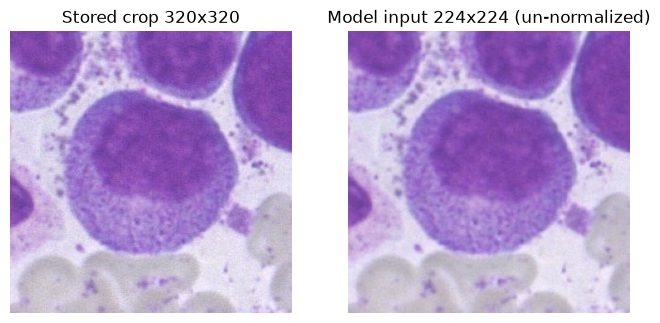

In [19]:
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMG_SIZE = 224

preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
print(preprocess)

# One real crop to inspect
example_path = sorted(Path("../data/crops").glob("*/promyelocyte/*.png"))[0]
img = Image.open(example_path).convert("RGB")
print("\n", example_path.name, img.size, img.mode)

x = preprocess(img)
print("Tensor shape:", tuple(x.shape), x.dtype)
print("Per-channel mean after normalization:", x.mean(dim=(1, 2)).numpy().round(3))
print("Per-channel std after normalization: ", x.std(dim=(1, 2)).numpy().round(3))

# Undo the normalization so we can look at what the model actually receives
shown = x * torch.tensor(IMAGENET_STD).view(3, 1, 1) + torch.tensor(IMAGENET_MEAN).view(3, 1, 1)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img)
axes[0].set_title(f"Stored crop {img.size[0]}x{img.size[1]}")
axes[1].imshow(shown.permute(1, 2, 0).clamp(0, 1))
axes[1].set_title("Model input 224x224 (un-normalized)")
for ax in axes:
    ax.axis("off")
plt.show()


In [20]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = model.to(device)
print("Device:", device)

# 4 promyelocytes + 4 segmented neutrophils (first files alphabetically)
crop_root = Path("../data/crops")
test_paths = (
    sorted(crop_root.glob("*/promyelocyte/*.png"))[:4]
    + sorted(crop_root.glob("*/segmented_neutrophil/*.png"))[:4]
)
batch = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in test_paths])
print("Batch shape:", tuple(batch.shape))

with torch.no_grad():
    out = model.forward_features(batch.to(device))
    direct = model(batch.to(device))

cls = out["x_norm_clstoken"]
patches = out["x_norm_patchtokens"]
print("CLS tokens:  ", tuple(cls.shape))
print("Patch tokens:", tuple(patches.shape))

# 2. Is model(x) the CLS token?
print("model(x) equals CLS token:", torch.allclose(direct, cls))

# 3. Same input twice -> identical output?
with torch.no_grad():
    cls_again = model.forward_features(batch.to(device))["x_norm_clstoken"]
print("Deterministic on", device, ":", torch.equal(cls, cls_again))

# 4. GPU (MPS) vs CPU
with torch.no_grad():
    cls_cpu = model.to("cpu").forward_features(batch)["x_norm_clstoken"]
model = model.to(device)

diff = (cls.cpu() - cls_cpu).abs().max().item()
cos = torch.nn.functional.cosine_similarity(cls.cpu(), cls_cpu).min().item()
print(f"MPS vs CPU: max abs difference {diff:.2e}, min cosine similarity {cos:.6f}")


Device: mps
Batch shape: (8, 3, 224, 224)
CLS tokens:   (8, 768)
Patch tokens: (8, 256, 768)
model(x) equals CLS token: True
Deterministic on mps : True
MPS vs CPU: max abs difference 3.55e-05, min cosine similarity 1.000000


In [21]:
import numpy as np
import pandas as pd

CROP_DIR = Path("../data/crops")

TARGET_STAGES = [
    "promyelocyte",
    "neutrophilic_myelocyte",
    "neutrophilic_metamyelocyte",
    "neutrophilic_band",
    "segmented_neutrophil",
]

# Verified in audit section 0.8 (IDC sm_instance_index + local WSI headers)
LOWRES_PATIENTS = {
    "67C6A1E7CE56D3D6FA748AB6D9AF3FD7",
    "A1D0C6E83F027327D8461063F4AC58A6",
}

metadata_files = sorted(CROP_DIR.glob("*/metadata.csv"))
meta = pd.concat(
    [pd.read_csv(p, dtype={"patient_id": str}) for p in metadata_files],
    ignore_index=True,
)

cells = meta[meta["label"].isin(TARGET_STAGES)].copy().reset_index(drop=True)

# Rebuild paths from patient/label/basename (low-res metadata paths are stale)
cells["basename"] = cells["filename"].map(lambda s: Path(s).name)
cells["image_path"] = [
    str(CROP_DIR / pid / label / name)
    for pid, label, name in zip(cells["patient_id"], cells["label"], cells["basename"])
]
cells["cell_id"] = cells["basename"].str.removesuffix(".png")

# Resolution metadata
is_lowres = cells["patient_id"].isin(LOWRES_PATIENTS)
cells["pixel_spacing_um"] = np.where(is_lowres, 0.194475, 0.110724)
cells["native_crop_px"] = np.where(is_lowres, 183, 320)
cells["resized_from_native"] = is_lowres

print("metadata.csv files:", len(metadata_files))
print("Cells (five stages):", len(cells))
print("Patients:", cells["patient_id"].nunique())
print("cell_id unique:", cells["cell_id"].is_unique)
print("All image files exist:", cells["image_path"].map(lambda p: Path(p).exists()).all())
print("\nCells per stage:")
print(cells["label"].value_counts().reindex(TARGET_STAGES).to_string())
print("\nCells by resolution:")
print(cells.groupby("native_crop_px")["patient_id"].agg(["size", "nunique"]).to_string())


metadata.csv files: 46
Cells (five stages): 8340
Patients: 46
cell_id unique: True
All image files exist: True

Cells per stage:
label
promyelocyte                  1510
neutrophilic_myelocyte        1460
neutrophilic_metamyelocyte     926
neutrophilic_band             1771
segmented_neutrophil          2673

Cells by resolution:
                size  nunique
native_crop_px               
183              907        2
320             7433       44


In [22]:
import time

BATCH_SIZE = 64
paths = cells["image_path"].tolist()

cls_list = []
patch_mean_list = []
start = time.time()

with torch.no_grad():
    for i in range(0, len(paths), BATCH_SIZE):
        batch_paths = paths[i : i + BATCH_SIZE]
        batch = torch.stack(
            [preprocess(Image.open(p).convert("RGB")) for p in batch_paths]
        ).to(device)

        out = model.forward_features(batch)
        cls_list.append(out["x_norm_clstoken"].cpu())
        patch_mean_list.append(out["x_norm_patchtokens"].mean(dim=1).cpu())

        if (i // BATCH_SIZE) % 20 == 0:
            print(f"{i + len(batch_paths):5d} / {len(paths)} cells   {time.time() - start:5.0f} s")

emb_cls = torch.cat(cls_list).numpy()
emb_patch_mean = torch.cat(patch_mean_list).numpy()
print(f"\nDone in {time.time() - start:.0f} s")


   64 / 8340 cells       2 s
 1344 / 8340 cells      27 s
 2624 / 8340 cells      52 s
 3904 / 8340 cells      76 s
 5184 / 8340 cells     101 s
 6464 / 8340 cells     127 s
 7744 / 8340 cells     152 s

Done in 165 s


In [23]:
print("CLS embeddings:       ", emb_cls.shape, emb_cls.dtype)
print("Mean-patch embeddings:", emb_patch_mean.shape, emb_patch_mean.dtype)
print("All values finite:", np.isfinite(emb_cls).all() and np.isfinite(emb_patch_mean).all())
print("Distinct CLS embeddings:", len(np.unique(emb_cls, axis=0)), "of", len(emb_cls))

# Row-alignment spot check: re-embed 5 random cells one at a time
# and compare with the row of the same index in emb_cls
rng = np.random.default_rng(0)
check_rows = rng.choice(len(cells), size=5, replace=False)

with torch.no_grad():
    for r in check_rows:
        x = preprocess(Image.open(cells.loc[r, "image_path"]).convert("RGB"))
        single = model(x.unsqueeze(0).to(device)).cpu().numpy()[0]
        cos = single @ emb_cls[r] / (np.linalg.norm(single) * np.linalg.norm(emb_cls[r]))
        print(f"row {r:5d}  {cells.loc[r, 'cell_id']}  cosine = {cos:.6f}")


CLS embeddings:        (8340, 768) float32
Mean-patch embeddings: (8340, 768) float32
All values finite: True
Distinct CLS embeddings: 8340 of 8340
row  5310  A87FF679A2F3E71D9181A67B7542122C_0318_segmented_neutrophil  cosine = 1.000000
row  4261  A1D0C6E83F027327D8461063F4AC58A6_0013_promyelocyte  cosine = 1.000000
row  2249  4E732CED3463D06DE0CA9A15B6153677_0252_promyelocyte  cosine = 1.000000
row  2567  642E92EFB79421734881B53E1E1B18B6_0257_promyelocyte  cosine = 1.000000
row  7090  D3D9446802A44259755D38E6D163E820_0300_segmented_neutrophil  cosine = 1.000000


In [24]:
import json
import datetime
import torchvision

OUT_DIR = Path("../data/embeddings/dinobloom_b")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Linked table: one row per embedding, in the same order
table = cells.drop(columns=["basename"]).rename(columns={"filename": "metadata_filename"})
table.insert(0, "embedding_row", np.arange(len(table)))

np.save(OUT_DIR / "emb_cls.npy", emb_cls)
np.save(OUT_DIR / "emb_patch_mean.npy", emb_patch_mean)
table.to_csv(OUT_DIR / "cells.csv", index=False)

provenance = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "model": "DinoBloom-B (frozen, teacher backbone)",
    "weights_file": "models/DinoBloom-B.pth",
    "weights_md5": "03e64e849bfb383f8400e2c95166f32c",
    "weights_source": "https://zenodo.org/records/10908163",
    "architecture": "torch.hub facebookresearch/dinov2 dinov2_vitb14, pretrained=False, pos_embed (1, 257, 768)",
    "preprocessing": str(preprocess),
    "embeddings": {
        "emb_cls.npy": "x_norm_clstoken (equals model(x))",
        "emb_patch_mean.npy": "mean over 256 x_norm_patchtokens",
    },
    "stored_crops": "320x320 PNG; low-res patients = 183 px native resized to 320 (bicubic) at extraction",
    "labels_used_for_embedding": False,
    "n_cells": int(len(table)),
    "device": str(device),
    "batch_size": BATCH_SIZE,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
}
(OUT_DIR / "provenance.json").write_text(json.dumps(provenance, indent=2))

for f in sorted(OUT_DIR.iterdir()):
    print(f"{f.name:22s} {f.stat().st_size / 1e6:6.1f} MB")


cells.csv                 3.9 MB
emb_cls.npy              25.6 MB
emb_patch_mean.npy       25.6 MB
provenance.json           0.0 MB


In [25]:
check_cls = np.load(OUT_DIR / "emb_cls.npy")
check_patch = np.load(OUT_DIR / "emb_patch_mean.npy")
check_table = pd.read_csv(OUT_DIR / "cells.csv", dtype={"patient_id": str})

print("CLS identical after reload:       ", np.array_equal(check_cls, emb_cls))
print("Mean-patch identical after reload:", np.array_equal(check_patch, emb_patch_mean))
print("Table rows:", len(check_table), "| embedding_row is 0..N-1:",
      (check_table["embedding_row"] == np.arange(len(check_table))).all())
print("cell_id order preserved:", (check_table["cell_id"] == cells["cell_id"]).all())
print("\nColumns:", list(check_table.columns))


CLS identical after reload:        True
Mean-patch identical after reload: True
Table rows: 8340 | embedding_row is 0..N-1: True
cell_id order preserved: True

Columns: ['embedding_row', 'annotation_index', 'label', 'bbox_x_min', 'bbox_y_min', 'bbox_x_max', 'bbox_y_max', 'bbox_width', 'bbox_height', 'patient_id', 'center_x', 'center_y', 'crop_x', 'crop_y', 'crop_size', 'metadata_filename', 'image_path', 'cell_id', 'pixel_spacing_um', 'native_crop_px', 'resized_from_native']


LATENT SPACE CHECKS

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

EMB_DIR = Path("../data/embeddings/dinobloom_b")

X = np.load(EMB_DIR / "emb_cls.npy")
cells = pd.read_csv(EMB_DIR / "cells.csv", dtype={"patient_id": str})

assert len(X) == len(cells)
assert (cells["embedding_row"] == np.arange(len(cells))).all()

import sklearn, scipy
print("scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("X:", X.shape, "| cells:", len(cells), "| patients:", cells["patient_id"].nunique())


scikit-learn 1.9.1 | scipy 1.17.1
X: (8340, 768) | cells: 8340 | patients: 46


## A. Pre-specified criteria

Representation: DinoBloom-B CLS embeddings, L2-normalized (cosine geometry).
Number of PCA components for graph/diffusion analyses is chosen from the
variance spectrum alone (no labels).

### Structure: assessed WITHOUT labels
- S1 Connectivity: in the symmetrized kNN graph, the largest connected
  component contains >= 99% of cells, for k = 10, 15 and 30.
- S2 Patient effect: report the fraction of each cell's k nearest neighbours
  from the same patient, vs. the fraction expected by chance.
  Patient identity is considered *dominant* if it explains most of the
  variance of the leading diffusion component (R^2 >= 0.5).
- S3 Technical confounders: report the correlation of leading PCs /
  diffusion components with bounding-box size and low-resolution status.
  A leading component mainly tracking these is not a candidate trajectory.
- S4 Diffusion spectrum: no group of several eigenvalues near 1
  (which would indicate disconnected clusters rather than a manifold).

### Validation: labels introduced only here
- V1 Neighbourhood: among a cell's neighbours with a different stage,
  the share that is an adjacent stage (|Δstage| = 1) exceeds the share
  expected under random label permutation.
- V2 Ordering: Spearman correlation between the candidate trajectory
  coordinate and stage order (1–5) is clearly non-zero, and stage medians
  are monotonic along it.
- V3 Within-patient: V2 holds in the majority of patients individually
  (same sign), not only in pooled data.

### Decision rule
Pseudotime is inferred only if S1–S4 pass and V1–V2 hold.
If S1 or S2 fail, we do NOT infer pseudotime; we report the structure
(clusters / patient effects) and decide separately, as a declared change,
whether any correction is justified.

### Sensitivity analyses (planned)
Without the two low-resolution patients; mean-patch embeddings;
DinoBloom-S; within-patient analyses.

**Amendment 2026-10-05 (after V2/V3, before V1):** added a check of stage
ordering along DC1 within bounding-box size quantiles (5 and 10 bins), plus
the ordering given by size alone, to assess the size association noted in E2
(DC1 vs bbox area rho = -0.53).



Embedding lengths before normalization: min 28.77, median 39.90, max 47.90

Component : variance share (cumulative)
  PC1   : 0.0733  (0.073)
  PC2   : 0.0636  (0.137)
  PC3   : 0.0405  (0.177)
  PC5   : 0.0263  (0.232)
  PC10  : 0.0174  (0.334)
  PC20  : 0.0100  (0.456)
  PC50  : 0.0039  (0.640)
  PC100 : 0.0018  (0.770)
  PC200 : 0.0007  (0.878)
Components needed for 50% of variance: 25
Components needed for 80% of variance: 120
Components needed for 90% of variance: 201


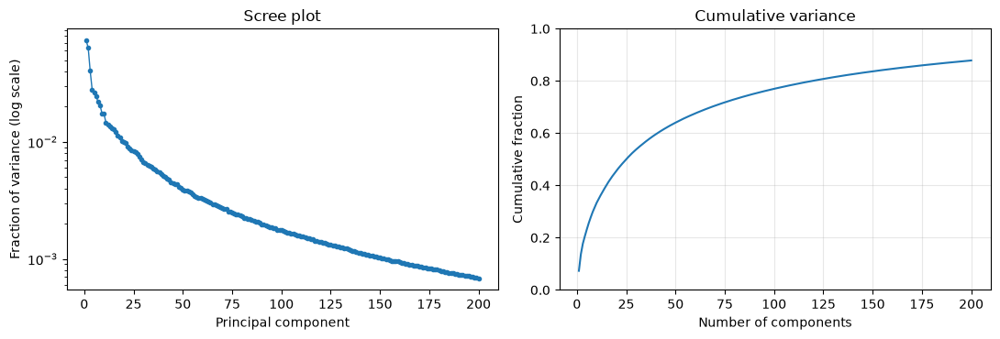

In [2]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. L2-normalize: every embedding becomes a unit vector (cosine geometry)
norms = np.linalg.norm(X, axis=1)
print(f"Embedding lengths before normalization: min {norms.min():.2f}, "
      f"median {np.median(norms):.2f}, max {norms.max():.2f}")
X_norm = X / norms[:, None]

# 2. PCA
N_PCS_FIT = 200
pca = PCA(n_components=N_PCS_FIT, random_state=0)
Z = pca.fit_transform(X_norm)

evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

# 3. Spectrum
print("\nComponent : variance share (cumulative)")
for n in [1, 2, 3, 5, 10, 20, 50, 100, 200]:
    print(f"  PC{n:<4d}: {evr[n-1]:.4f}  ({cum[n-1]:.3f})")
for target in [0.5, 0.8, 0.9]:
    print(f"Components needed for {target:.0%} of variance: {np.searchsorted(cum, target) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(np.arange(1, N_PCS_FIT + 1), evr, marker=".", lw=1)
axes[0].set_yscale("log")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Fraction of variance (log scale)")
axes[0].set_title("Scree plot")
axes[1].plot(np.arange(1, N_PCS_FIT + 1), cum)
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative fraction")
axes[1].set_title("Cumulative variance")
plt.tight_layout()
plt.show()


In [3]:
from scipy.stats import spearmanr

N_PCS = 50   # primary choice; 20 and 100 as sensitivity later

def r2_by_group(values, groups):
    """Share of variance in `values` explained by group means (one-way ANOVA R^2)."""
    df = pd.DataFrame({"v": values, "g": groups})
    group_means = df.groupby("g")["v"].transform("mean")
    ss_within = ((df["v"] - group_means) ** 2).sum()
    ss_total = ((df["v"] - df["v"].mean()) ** 2).sum()
    return 1 - ss_within / ss_total

# Technical covariates (no stage labels)
spacing = cells["pixel_spacing_um"]
cells["bbox_area_um2"] = cells["bbox_width"] * cells["bbox_height"] * spacing**2
cells["embedding_norm"] = norms
lowres = cells["resized_from_native"]

rows = []
for i in range(10):
    pc = Z[:, i]
    rows.append({
        "PC": i + 1,
        "var_share": evr[i],
        "R2_patient": r2_by_group(pc, cells["patient_id"]),
        "R2_lowres": r2_by_group(pc, lowres),
        "rho_bbox_area": spearmanr(pc, cells["bbox_area_um2"]).statistic,
        "rho_emb_norm": spearmanr(pc, cells["embedding_norm"]).statistic,
    })

pc_covariates = pd.DataFrame(rows).set_index("PC")
print(pc_covariates.round(3).to_string())

print("\nEmbedding norm vs bbox area, rho:",
      round(spearmanr(cells["embedding_norm"], cells["bbox_area_um2"]).statistic, 3))
print("Embedding norm, R2 by patient:", round(r2_by_group(cells["embedding_norm"], cells["patient_id"]), 3))


    var_share  R2_patient  R2_lowres  rho_bbox_area  rho_emb_norm
PC                                                               
1       0.073       0.396      0.003          0.299         0.634
2       0.064       0.296      0.009          0.397         0.103
3       0.040       0.547      0.086         -0.143         0.068
4       0.028       0.191      0.010          0.103         0.314
5       0.026       0.305      0.032         -0.384        -0.068
6       0.025       0.262      0.008          0.220         0.165
7       0.022       0.226      0.006          0.111        -0.039
8       0.021       0.481      0.082         -0.031         0.184
9       0.018       0.237      0.003         -0.054         0.183
10      0.017       0.134      0.054          0.087        -0.104

Embedding norm vs bbox area, rho: 0.285
Embedding norm, R2 by patient: 0.224


In [4]:
from sklearn.neighbors import NearestNeighbors

K = 15
Zk = Z[:, :N_PCS]

nn_model = NearestNeighbors(n_neighbors=K + 1).fit(Zk)
dist, idx = nn_model.kneighbors(Zk)

# Each cell's nearest "neighbour" is itself (distance 0); check, then drop it
assert (idx[:, 0] == np.arange(len(Zk))).all()
idx = idx[:, 1:]

pid = cells["patient_id"].to_numpy()
same_patient_frac = (pid[idx] == pid[:, None]).mean(axis=1)

patient_n = cells["patient_id"].map(cells["patient_id"].value_counts()).to_numpy()
expected_frac = (patient_n - 1) / (len(cells) - 1)

print(f"k = {K}, {N_PCS} PCs")
print(f"Mean same-patient neighbour fraction: observed {same_patient_frac.mean():.3f}, "
      f"expected by chance {expected_frac.mean():.3f}, "
      f"ratio {same_patient_frac.mean() / expected_frac.mean():.1f}x")

per_patient = (
    pd.DataFrame({
        "patient_id": pid,
        "observed": same_patient_frac,
        "expected": expected_frac,
        "lowres": cells["resized_from_native"],
    })
    .groupby("patient_id")
    .agg(n=("observed", "size"), observed=("observed", "mean"),
         expected=("expected", "first"), lowres=("lowres", "first"))
    .sort_values("observed", ascending=False)
)

print("\nPer-patient observed same-patient fraction:")
print(per_patient["observed"].describe().round(3).to_string())
print("\nHighest 5 patients:")
print(per_patient.head(5).round(3).to_string())
print("\nLowest 5 patients:")
print(per_patient.tail(5).round(3).to_string())
print("\nLow-res patients:")
print(per_patient[per_patient["lowres"]].round(3).to_string())


k = 15, 50 PCs
Mean same-patient neighbour fraction: observed 0.408, expected by chance 0.025, ratio 16.1x

Per-patient observed same-patient fraction:
count    46.000
mean      0.381
std       0.144
min       0.113
25%       0.281
50%       0.343
75%       0.483
max       0.811

Highest 5 patients:
                                    n  observed  expected  lowres
patient_id                                                       
67C6A1E7CE56D3D6FA748AB6D9AF3FD7  419     0.811     0.050    True
A5771BCE93E200C36F7CD9DFD0E5DEAA  242     0.713     0.029   False
9BF31C7FF062936A96D3C8BD1F8F2FF3  142     0.631     0.017   False
A1D0C6E83F027327D8461063F4AC58A6  488     0.566     0.058    True
182BE0C5CDCD5072BB1864CDEE4D3D6E  229     0.554     0.027   False

Lowest 5 patients:
                                    n  observed  expected  lowres
patient_id                                                       
6C8349CC7260AE62E3B1396831A8398F  210     0.229     0.025   False
F7177163C833DFF4B38

In [5]:
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph

rows = []
for n_pcs in [20, 50, 100]:
    for k in [10, 15, 30]:
        A = kneighbors_graph(Z[:, :n_pcs], n_neighbors=k, mode="connectivity", include_self=False)
        for rule, G in [("union", A.maximum(A.T)), ("mutual", A.minimum(A.T))]:
            n_comp, comp = connected_components(G, directed=False)
            sizes = np.sort(np.bincount(comp))[::-1]
            rows.append({
                "n_pcs": n_pcs, "k": k, "rule": rule,
                "n_components": n_comp,
                "largest_frac": sizes[0] / len(cells),
                "next_sizes": list(sizes[1:6]),
            })

connectivity = pd.DataFrame(rows)
print(connectivity.round(4).to_string(index=False))


 n_pcs  k   rule  n_components  largest_frac      next_sizes
    20 10  union             1        1.0000              []
    20 10 mutual            44        0.9948 [1, 1, 1, 1, 1]
    20 15  union             1        1.0000              []
    20 15 mutual            10        0.9989 [1, 1, 1, 1, 1]
    20 30  union             1        1.0000              []
    20 30 mutual             2        0.9999             [1]
    50 10  union             1        1.0000              []
    50 10 mutual            61        0.9924 [2, 2, 2, 1, 1]
    50 15  union             1        1.0000              []
    50 15 mutual            12        0.9986 [2, 1, 1, 1, 1]
    50 30  union             1        1.0000              []
    50 30 mutual             2        0.9999             [1]
   100 10  union             1        1.0000              []
   100 10 mutual            80        0.9900 [2, 2, 2, 2, 1]
   100 15  union             1        1.0000              []
   100 15 mutual        

Eigenvalues: [1.     0.9523 0.9347 0.9047 0.8941 0.8864 0.8606 0.8561 0.8532 0.8437
 0.8329 0.8289 0.8256 0.8121 0.8073 0.8001]
Trivial component constant? relative spread: 1.01e-15


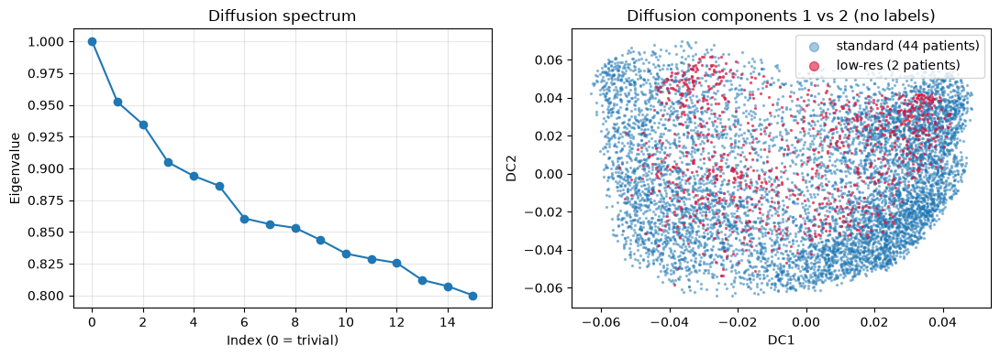

In [6]:
from scipy.sparse import csr_matrix, diags
from scipy.sparse.linalg import eigsh

K_DM = 15
n = len(Zk)

# Neighbours in the primary 50-PC space (recomputed here so this cell stands alone)
nn_dm = NearestNeighbors(n_neighbors=K_DM + 1).fit(Zk)
d, nbr = nn_dm.kneighbors(Zk)
assert (nbr[:, 0] == np.arange(n)).all()
d, nbr = d[:, 1:], nbr[:, 1:]

# 1. Gaussian kernel with local scaling
sigma = d[:, -1]                                  # distance to k-th neighbour
rows_i = np.repeat(np.arange(n), K_DM)
cols_j = nbr.ravel()
w = np.exp(-d.ravel() ** 2 / (sigma[rows_i] * sigma[cols_j]))
W = csr_matrix((w, (rows_i, cols_j)), shape=(n, n))
W = W.maximum(W.T)                                # symmetric (union rule)

# 2. Density normalization (alpha = 1)
q = np.asarray(W.sum(axis=1)).ravel()
W_tilde = diags(1 / q) @ W @ diags(1 / q)

# 3-4. Random-walk eigenvectors via the equivalent symmetric matrix
row_sum = np.asarray(W_tilde.sum(axis=1)).ravel()
M_sym = diags(row_sum ** -0.5) @ W_tilde @ diags(row_sum ** -0.5)

N_EIG = 16
v0 = np.random.default_rng(0).random(n)           # fixed start vector -> reproducible
evals, evecs = eigsh(M_sym, k=N_EIG, which="LA", v0=v0)
order = np.argsort(evals)[::-1]
evals, evecs = evals[order], evecs[:, order]
psi = evecs * (row_sum ** -0.5)[:, None]          # random-walk eigenvectors

# Checks
print("Eigenvalues:", np.round(evals, 4))
print("Trivial component constant? relative spread:",
      f"{psi[:, 0].std() / abs(psi[:, 0].mean()):.2e}")

DC = psi[:, 1:]                                   # diffusion components DC1, DC2, ...

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(N_EIG), evals, marker="o")
axes[0].set_xlabel("Index (0 = trivial)")
axes[0].set_ylabel("Eigenvalue")
axes[0].set_title("Diffusion spectrum")
axes[0].grid(alpha=0.3)

lr = cells["resized_from_native"].to_numpy()
axes[1].scatter(DC[~lr, 0], DC[~lr, 1], s=2, alpha=0.4, label="standard (44 patients)")
axes[1].scatter(DC[lr, 0], DC[lr, 1], s=2, alpha=0.6, color="crimson", label="low-res (2 patients)")
axes[1].set_xlabel("DC1")
axes[1].set_ylabel("DC2")
axes[1].set_title("Diffusion components 1 vs 2 (no labels)")
axes[1].legend(markerscale=5)
plt.tight_layout()
plt.show()


    eigenvalue  R2_patient  R2_lowres  rho_bbox_area  rho_emb_norm
DC                                                                
1        0.952       0.068      0.001         -0.533        -0.475
2        0.935       0.688      0.020         -0.025        -0.410
3        0.905       0.763      0.352         -0.095         0.061
4        0.894       0.620      0.096          0.188        -0.022
5        0.886       0.180      0.018         -0.020        -0.051

Spearman correlation of DCs with PCs:
      PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8   PC9  PC10
DC1 -0.64 -0.69  0.05  0.02  0.05 -0.05 -0.14  0.04 -0.04 -0.05
DC2 -0.74  0.58  0.14  0.00  0.04  0.00  0.01 -0.06  0.02  0.02
DC3  0.20 -0.17  0.74 -0.32 -0.14  0.07 -0.12 -0.06 -0.01 -0.17
DC4 -0.07 -0.07 -0.34  0.30 -0.45 -0.19  0.22 -0.35 -0.05  0.02
DC5  0.07 -0.24  0.27 -0.08 -0.12 -0.07  0.40  0.01 -0.02  0.38


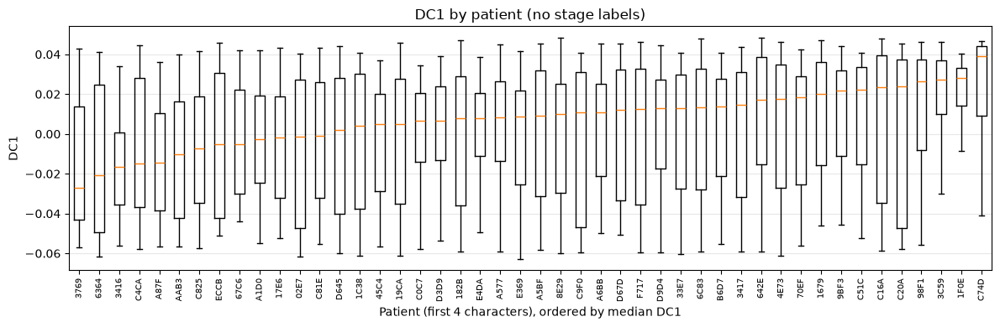

In [7]:
rows = []
for i in range(5):
    dc = DC[:, i]
    rows.append({
        "DC": i + 1,
        "eigenvalue": evals[i + 1],
        "R2_patient": r2_by_group(dc, cells["patient_id"]),
        "R2_lowres": r2_by_group(dc, cells["resized_from_native"]),
        "rho_bbox_area": spearmanr(dc, cells["bbox_area_um2"]).statistic,
        "rho_emb_norm": spearmanr(dc, cells["embedding_norm"]).statistic,
    })
dc_covariates = pd.DataFrame(rows).set_index("DC")
print(dc_covariates.round(3).to_string())

# Which PCs is each DC built from? (Spearman with PC1..PC10)
pc_links = pd.DataFrame(
    [[spearmanr(DC[:, i], Z[:, j]).statistic for j in range(10)] for i in range(5)],
    index=[f"DC{i+1}" for i in range(5)],
    columns=[f"PC{j+1}" for j in range(10)],
)
print("\nSpearman correlation of DCs with PCs:")
print(pc_links.round(2).to_string())

# DC1 distribution per patient, patients ordered by their median DC1
dc1 = pd.DataFrame({"patient_id": cells["patient_id"], "DC1": DC[:, 0]})
patient_order = dc1.groupby("patient_id")["DC1"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 4))
ax.boxplot(
    [dc1.loc[dc1["patient_id"] == p, "DC1"] for p in patient_order],
    showfliers=False,
)
ax.set_xticks(range(1, len(patient_order) + 1))
ax.set_xticklabels([p[:4] for p in patient_order], rotation=90, fontsize=7)
ax.set_xlabel("Patient (first 4 characters), ordered by median DC1")
ax.set_ylabel("DC1")
ax.set_title("DC1 by patient (no stage labels)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
def diffusion_map(Y, k=15, n_eig=6, seed=0):
    """Diffusion map with local-scaling Gaussian kernel and density normalization.
    Returns eigenvalues (incl. trivial) and diffusion components (trivial removed)."""
    n = len(Y)
    d, nbr = NearestNeighbors(n_neighbors=k + 1).fit(Y).kneighbors(Y)
    assert (nbr[:, 0] == np.arange(n)).all()
    d, nbr = d[:, 1:], nbr[:, 1:]

    sigma = d[:, -1]
    rows_i = np.repeat(np.arange(n), k)
    cols_j = nbr.ravel()
    w = np.exp(-d.ravel() ** 2 / (sigma[rows_i] * sigma[cols_j]))
    W = csr_matrix((w, (rows_i, cols_j)), shape=(n, n))
    W = W.maximum(W.T)

    q = np.asarray(W.sum(axis=1)).ravel()
    W_tilde = diags(1 / q) @ W @ diags(1 / q)
    row_sum = np.asarray(W_tilde.sum(axis=1)).ravel()
    M_sym = diags(row_sum ** -0.5) @ W_tilde @ diags(row_sum ** -0.5)

    v0 = np.random.default_rng(seed).random(n)
    vals, vecs = eigsh(M_sym, k=n_eig, which="LA", v0=v0)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    psi = vecs * (row_sum ** -0.5)[:, None]
    return vals, psi[:, 1:]

# Check: the function reproduces Step E1
vals_check, DC_check = diffusion_map(Z[:, :50], k=15)
print("Reproduces E1 DC1 (|rho|):", round(abs(spearmanr(DC_check[:, 0], DC[:, 0]).statistic), 6))

# Sensitivity grid
dc1_primary = DC[:, 0]
rows = []
for n_pcs in [20, 50, 100]:
    for k in [10, 15, 30]:
        vals, dcs = diffusion_map(Z[:, :n_pcs], k=k)
        rows.append({
            "subset": "all 46", "n_pcs": n_pcs, "k": k,
            "lambda1": vals[1], "lambda2": vals[2],
            "abs_rho_vs_primary_DC1": abs(spearmanr(dcs[:, 0], dc1_primary).statistic),
            "R2_patient_DC1": r2_by_group(dcs[:, 0], cells["patient_id"]),
        })

# Standard-resolution patients only (PCA kept from all cells; graph rebuilt on subset)
std = ~cells["resized_from_native"].to_numpy()
vals, dcs = diffusion_map(Z[std, :50], k=15)
rows.append({
    "subset": "44 standard", "n_pcs": 50, "k": 15,
    "lambda1": vals[1], "lambda2": vals[2],
    "abs_rho_vs_primary_DC1": abs(spearmanr(dcs[:, 0], dc1_primary[std]).statistic),
    "R2_patient_DC1": r2_by_group(dcs[:, 0], cells.loc[std, "patient_id"]),
})

stability = pd.DataFrame(rows)
print(stability.round(3).to_string(index=False))


Reproduces E1 DC1 (|rho|): 1.0
     subset  n_pcs  k  lambda1  lambda2  abs_rho_vs_primary_DC1  R2_patient_DC1
     all 46     20 10    0.967    0.954                   0.991           0.066
     all 46     20 15    0.962    0.946                   0.992           0.065
     all 46     20 30    0.952    0.931                   0.992           0.065
     all 46     50 10    0.958    0.945                   0.998           0.069
     all 46     50 15    0.952    0.935                   1.000           0.068
     all 46     50 30    0.943    0.918                   0.997           0.066
     all 46    100 10    0.954    0.941                   0.995           0.075
     all 46    100 15    0.948    0.930                   0.997           0.071
     all 46    100 30    0.939    0.912                   0.996           0.066
44 standard     50 15    0.954    0.936                   0.999           0.071


Saved label-free diffusion components: label_free_diffusion_pc50_k15.csv

Spearman rho with stage order (1-5):
  DC1: +0.844
  DC2: -0.099
  DC3: +0.168
  DC4: -0.060
  DC5: +0.113

DC1 (oriented) by stage:
                             count     25%     50%     75%
label                                                     
promyelocyte                1510.0 -0.0520 -0.0456 -0.0372
neutrophilic_myelocyte      1460.0 -0.0361 -0.0270 -0.0162
neutrophilic_metamyelocyte   926.0 -0.0139  0.0014  0.0141
neutrophilic_band           1771.0  0.0067  0.0190  0.0280
segmented_neutrophil        2673.0  0.0205  0.0304  0.0370
Medians monotonic increasing: True


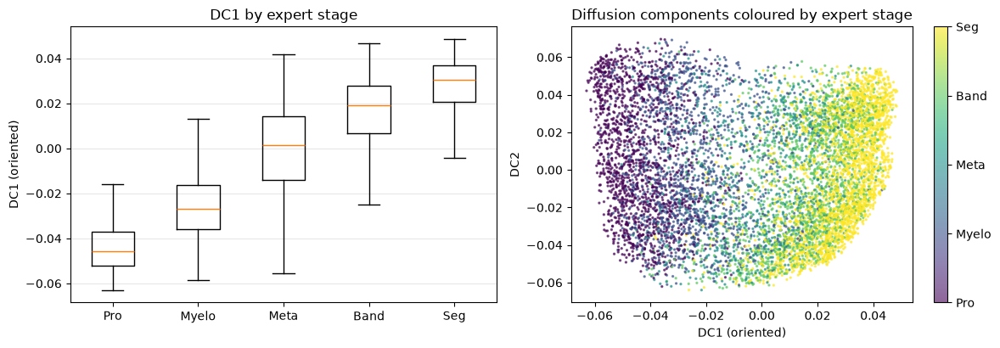

In [9]:
# F0. Freeze label-free results (written before any label is used)
label_free = pd.DataFrame({"embedding_row": cells["embedding_row"]})
for i in range(5):
    label_free[f"DC{i+1}"] = DC[:, i]
label_free.to_csv(EMB_DIR / "label_free_diffusion_pc50_k15.csv", index=False)
print("Saved label-free diffusion components:", (EMB_DIR / "label_free_diffusion_pc50_k15.csv").name)

# F1. Labels enter here, for validation only
TARGET_STAGES = [
    "promyelocyte",
    "neutrophilic_myelocyte",
    "neutrophilic_metamyelocyte",
    "neutrophilic_band",
    "segmented_neutrophil",
]
stage_number = {s: i for i, s in enumerate(TARGET_STAGES, start=1)}
stage = cells["label"].map(stage_number).to_numpy()

print("\nSpearman rho with stage order (1-5):")
for i in range(5):
    print(f"  DC{i+1}: {spearmanr(DC[:, i], stage).statistic:+.3f}")

# Orient DC1 for display only: stage 1 at low values
rho_dc1 = spearmanr(DC[:, 0], stage).statistic
dc1_display = DC[:, 0] * np.sign(rho_dc1)

per_stage = (
    pd.DataFrame({"label": cells["label"], "DC1": dc1_display})
    .groupby("label")["DC1"]
    .describe()[["count", "25%", "50%", "75%"]]
    .reindex(TARGET_STAGES)
)
print("\nDC1 (oriented) by stage:")
print(per_stage.round(4).to_string())
print("Medians monotonic increasing:", per_stage["50%"].is_monotonic_increasing)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].boxplot(
    [dc1_display[stage == s] for s in range(1, 6)],
    showfliers=False,
)
axes[0].set_xticks(range(1, 6))
axes[0].set_xticklabels(["Pro", "Myelo", "Meta", "Band", "Seg"])
axes[0].set_ylabel("DC1 (oriented)")
axes[0].set_title("DC1 by expert stage")
axes[0].grid(axis="y", alpha=0.3)

sc = axes[1].scatter(dc1_display, DC[:, 1], c=stage, cmap="viridis", s=2, alpha=0.6)
axes[1].set_xlabel("DC1 (oriented)")
axes[1].set_ylabel("DC2")
axes[1].set_title("Diffusion components coloured by expert stage")
cbar = fig.colorbar(sc, ax=axes[1], ticks=range(1, 6))
cbar.ax.set_yticklabels(["Pro", "Myelo", "Meta", "Band", "Seg"])
plt.tight_layout()
plt.show()


Patients with rho > 0: 46 / 46
Patients with monotonic stage medians: 46 / 46

Within-patient rho:
count    46.000
mean      0.841
std       0.062
min       0.567
25%       0.813
50%       0.859
75%       0.876
max       0.934

Lowest 5 patients:
                      patient_id   n  n_stages   rho  medians_monotonic  lowres
1F0E3DAD99908345F7439F8FFABDFFC4 133         4 0.567               True   False
3C59DC048E8850243BE8079A5C74D079 157         5 0.714               True   False
E4DA3B7FBBCE2345D7772B0674A318D5 202         5 0.754               True   False
9BF31C7FF062936A96D3C8BD1F8F2FF3 142         5 0.776               True   False
98F13708210194C475687BE6106A3B84 177         5 0.780               True   False

Low-res patients:
                      patient_id   n  n_stages   rho  medians_monotonic  lowres
A1D0C6E83F027327D8461063F4AC58A6 488         5 0.817               True    True
67C6A1E7CE56D3D6FA748AB6D9AF3FD7 419         5 0.838               True    True


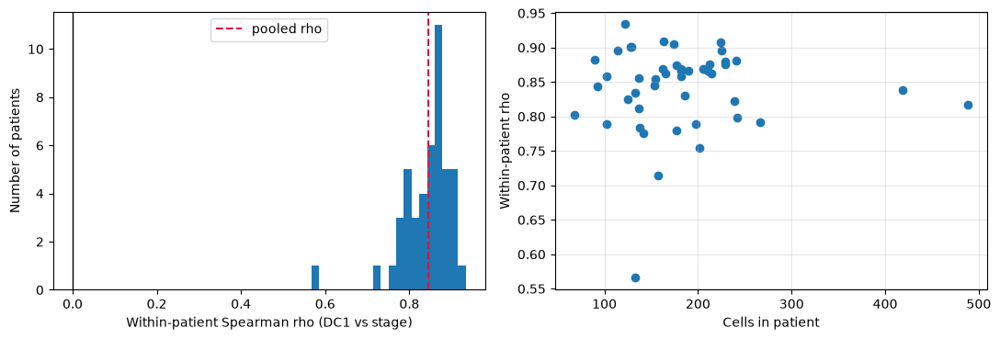

In [10]:
rows = []
for patient, group in cells.groupby("patient_id"):
    r = group.index.to_numpy()                     # row numbers of this patient's cells
    st = stage[r]
    medians = pd.Series(dc1_display[r]).groupby(st).median()
    rows.append({
        "patient_id": patient,
        "n": len(r),
        "n_stages": len(np.unique(st)),
        "rho": spearmanr(dc1_display[r], st).statistic,
        "medians_monotonic": medians.is_monotonic_increasing,
        "lowres": group["resized_from_native"].iloc[0],
    })

v3 = pd.DataFrame(rows).sort_values("rho")

print(f"Patients with rho > 0: {(v3['rho'] > 0).sum()} / {len(v3)}")
print(f"Patients with monotonic stage medians: {v3['medians_monotonic'].sum()} / {len(v3)}")
print("\nWithin-patient rho:")
print(v3["rho"].describe().round(3).to_string())
print("\nLowest 5 patients:")
print(v3.head(5).round(3).to_string(index=False))
print("\nLow-res patients:")
print(v3[v3["lowres"]].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(v3["rho"], bins=20)
axes[0].axvline(0, color="black", lw=1)
axes[0].axvline(rho_dc1 * np.sign(rho_dc1), color="crimson", ls="--", label="pooled rho")
axes[0].set_xlabel("Within-patient Spearman rho (DC1 vs stage)")
axes[0].set_ylabel("Number of patients")
axes[0].legend()
axes[1].scatter(v3["n"], v3["rho"])
axes[1].set_xlabel("Cells in patient")
axes[1].set_ylabel("Within-patient rho")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


DC1 vs stage, all cells:        rho = +0.844
Size alone vs stage, all cells: rho = -0.555
DC1 vs size, all cells:         rho = -0.533
DC1 with size removed vs stage: rho = +0.660

5 size bins (1 = smallest cells):
 bin    n area_um2  rho_DC1_stage  rho_size_stage_in_bin    counts Pro/My/Me/Ba/Se
   1 1671   48-170          0.535                 -0.233  [13, 131, 173, 433, 921]
   2 1666  170-198          0.700                 -0.054  [49, 218, 240, 471, 688]
   3 1667  198-228          0.786                 -0.099 [146, 249, 225, 470, 577]
   4 1668  228-279          0.877                 -0.191 [386, 395, 183, 318, 386]
   5 1668  279-775          0.718                 -0.287  [916, 467, 105, 79, 101]

10 size bins (1 = smallest cells):
 bin   n area_um2  rho_DC1_stage  rho_size_stage_in_bin   counts Pro/My/Me/Ba/Se
   1 834   48-149          0.446                 -0.215    [4, 45, 64, 179, 542]
   2 837  149-170          0.610                 -0.036   [9, 86, 109, 254, 379]
   3 834

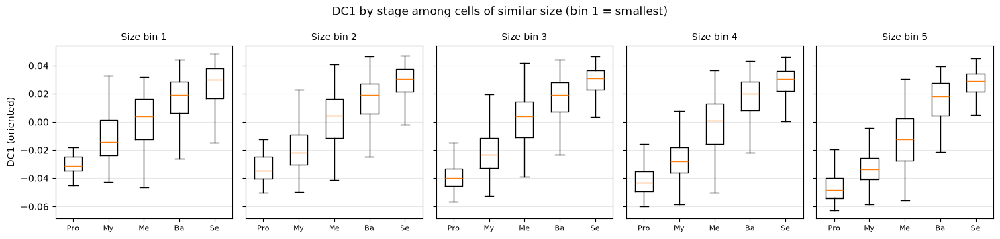

In [11]:
# Cell size in µm² (recomputed here so the cell stands alone)
area = (cells["bbox_width"] * cells["bbox_height"] * cells["pixel_spacing_um"] ** 2).to_numpy()

print(f"DC1 vs stage, all cells:        rho = {spearmanr(dc1_display, stage).statistic:+.3f}")
print(f"Size alone vs stage, all cells: rho = {spearmanr(area, stage).statistic:+.3f}")
print(f"DC1 vs size, all cells:         rho = {spearmanr(dc1_display, area).statistic:+.3f}")

# Partial correlation: remove the (rank-)linear effect of size from DC1, then correlate with stage
from scipy.stats import rankdata
r_dc1 = rankdata(dc1_display)
r_area = rankdata(area)
slope, intercept = np.polyfit(r_area, r_dc1, 1)
dc1_residual = r_dc1 - (slope * r_area + intercept)
print(f"DC1 with size removed vs stage: rho = {spearmanr(dc1_residual, stage).statistic:+.3f}")

# Within size bins
for n_bins in [5, 10]:
    size_bin = pd.qcut(area, q=n_bins, labels=False)
    rows = []
    for b in range(n_bins):
        m = size_bin == b
        rows.append({
            "bin": b + 1,
            "n": int(m.sum()),
            "area_um2": f"{area[m].min():.0f}-{area[m].max():.0f}",
            "rho_DC1_stage": spearmanr(dc1_display[m], stage[m]).statistic,
            "rho_size_stage_in_bin": spearmanr(area[m], stage[m]).statistic,
            "counts Pro/My/Me/Ba/Se": np.bincount(stage[m], minlength=6)[1:].tolist(),
        })
    print(f"\n{n_bins} size bins (1 = smallest cells):")
    print(pd.DataFrame(rows).round(3).to_string(index=False))

# Picture: DC1 by stage within each of the 5 size bins
size_bin5 = pd.qcut(area, q=5, labels=False)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
for b, ax in enumerate(axes):
    m = size_bin5 == b
    ax.boxplot([dc1_display[m & (stage == s)] for s in range(1, 6)], showfliers=False)
    ax.set_xticks(range(1, 6))
    ax.set_xticklabels(["Pro", "My", "Me", "Ba", "Se"], fontsize=8)
    ax.set_title(f"Size bin {b + 1}", fontsize=10)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("DC1 (oriented)")
plt.suptitle("DC1 by stage among cells of similar size (bin 1 = smallest)")
plt.tight_layout()
plt.show()


In [12]:
K_V1 = 15
nbrs = NearestNeighbors(n_neighbors=K_V1 + 1).fit(Zk).kneighbors(Zk, return_distance=False)
assert (nbrs[:, 0] == np.arange(len(Zk))).all()
nbrs = nbrs[:, 1:]

# All (cell, neighbour) pairs as two flat arrays
cell_i = np.repeat(np.arange(len(Zk)), K_V1)
nbr_j = nbrs.ravel()

def neighbour_stats(s):
    gap = np.abs(s[cell_i] - s[nbr_j])
    same = (gap == 0).mean()
    adjacent_among_different = (gap[gap > 0] == 1).mean()
    return same, adjacent_among_different

obs_same, obs_adj = neighbour_stats(stage)

rng = np.random.default_rng(0)
patient_rows = [g.index.to_numpy() for _, g in cells.groupby("patient_id")]

def shuffle_within_patients(s):
    out = s.copy()
    for r in patient_rows:
        out[r] = rng.permutation(s[r])
    return out

N_PERM = 200
null_global = np.array([neighbour_stats(rng.permutation(stage)) for _ in range(N_PERM)])
null_within = np.array([neighbour_stats(shuffle_within_patients(stage)) for _ in range(N_PERM)])

print(f"{'':28s}{'observed':>10s}{'global null':>14s}{'within-patient null':>22s}")
print(f"{'Same-stage neighbours':28s}{obs_same:10.3f}"
      f"{null_global[:, 0].mean():14.3f}{null_within[:, 0].mean():22.3f}")
print(f"{'Adjacent among different':28s}{obs_adj:10.3f}"
      f"{null_global[:, 1].mean():14.3f}{null_within[:, 1].mean():22.3f}")
print(f"\nNull maxima over {N_PERM} shuffles: same-stage {null_within[:, 0].max():.3f}, "
      f"adjacent {null_within[:, 1].max():.3f} (within-patient)")

# Neighbour composition: rows = cell's stage, columns = neighbour's stage
short = ["Pro", "Myelo", "Meta", "Band", "Seg"]
composition = pd.crosstab(
    pd.Categorical(stage[cell_i], categories=range(1, 6)),
    pd.Categorical(stage[nbr_j], categories=range(1, 6)),
    normalize="index",
)
composition.index = short
composition.columns = short
print("\nFraction of neighbours by stage (rows: cell's own stage):")
print(composition.round(2).to_string())


                              observed   global null   within-patient null
Same-stage neighbours            0.572         0.223                 0.231
Adjacent among different         0.794         0.368                 0.369

Null maxima over 200 shuffles: same-stage 0.235, adjacent 0.375 (within-patient)

Fraction of neighbours by stage (rows: cell's own stage):
        Pro  Myelo  Meta  Band   Seg
Pro    0.68   0.26  0.04  0.01  0.01
Myelo  0.28   0.47  0.13  0.08  0.04
Meta   0.07   0.22  0.29  0.31  0.11
Band   0.01   0.06  0.15  0.45  0.32
Seg    0.01   0.02  0.03  0.19  0.74


Orientation sign applied to DC1: 1
Pseudotime range: 0.000 - 1.000
Spearman with stage: +0.844  (should match DC1: 0.844)
Patient R2: 0.068  (should match DC1: ~0.07)
Largest gap between consecutive cells: 0.0069 at pseudotime 0.017
Median gap: 0.000073

Pseudotime by stage:
                             count    25%    50%    75%
label                                                  
promyelocyte                1510.0  0.098  0.155  0.231
neutrophilic_myelocyte      1460.0  0.241  0.322  0.419
neutrophilic_metamyelocyte   926.0  0.440  0.577  0.691
neutrophilic_band           1771.0  0.625  0.735  0.816
segmented_neutrophil        2673.0  0.748  0.837  0.896

Saved: pseudotime_optionA_dc1_pc50_k15.csv


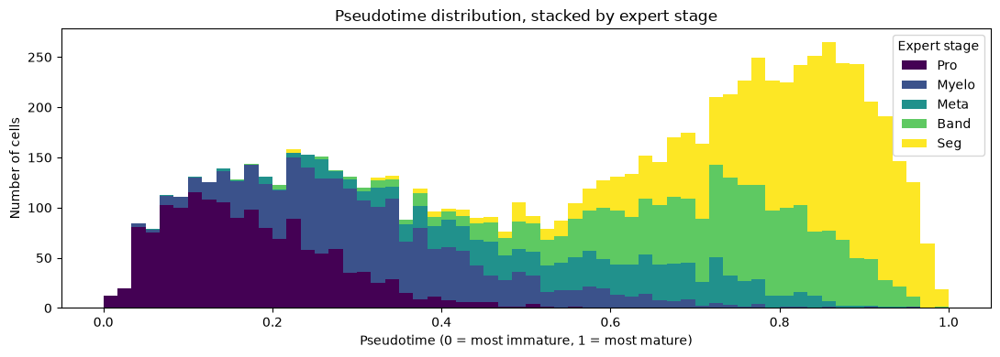

In [13]:
# 1. Orientation: the ONLY use of labels in constructing the pseudotime (direction only)
dc1_raw = DC[:, 0]
orientation = np.sign(spearmanr(dc1_raw, stage).statistic)
dc1_oriented = dc1_raw * orientation

# 2. Rescale to 0-1
pseudotime = (dc1_oriented - dc1_oriented.min()) / (dc1_oriented.max() - dc1_oriented.min())

# 3. Checks
print("Orientation sign applied to DC1:", int(orientation))
print(f"Pseudotime range: {pseudotime.min():.3f} - {pseudotime.max():.3f}")
print(f"Spearman with stage: {spearmanr(pseudotime, stage).statistic:+.3f}  (should match DC1: 0.844)")
print(f"Patient R2: {r2_by_group(pseudotime, cells['patient_id']):.3f}  (should match DC1: ~0.07)")

# Gap check: largest jump between consecutive cells along pseudotime
sorted_pt = np.sort(pseudotime)
gaps = np.diff(sorted_pt)
print(f"Largest gap between consecutive cells: {gaps.max():.4f} at pseudotime {sorted_pt[gaps.argmax()]:.3f}")
print(f"Median gap: {np.median(gaps):.6f}")

print("\nPseudotime by stage:")
print(
    pd.DataFrame({"label": cells["label"], "pt": pseudotime})
    .groupby("label")["pt"].describe()[["count", "5%" if False else "25%", "50%", "75%"]]
    .reindex(TARGET_STAGES).round(3).to_string()
)

# 4. Save
pt_table = cells[["embedding_row", "cell_id", "patient_id", "label", "resized_from_native"]].copy()
pt_table["DC1_raw"] = dc1_raw
pt_table["pseudotime"] = pseudotime
pt_path = EMB_DIR / "pseudotime_optionA_dc1_pc50_k15.csv"
pt_table.to_csv(pt_path, index=False)
print("\nSaved:", pt_path.name)

# 5. Distribution, stacked by stage
colors = plt.cm.viridis(np.linspace(0, 1, 5))
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(
    [pseudotime[stage == s] for s in range(1, 6)],
    bins=60, stacked=True, color=colors, label=short,
)
ax.set_xlabel("Pseudotime (0 = most immature, 1 = most mature)")
ax.set_ylabel("Number of cells")
ax.set_title("Pseudotime distribution, stacked by expert stage")
ax.legend(title="Expert stage")
plt.tight_layout()
plt.show()


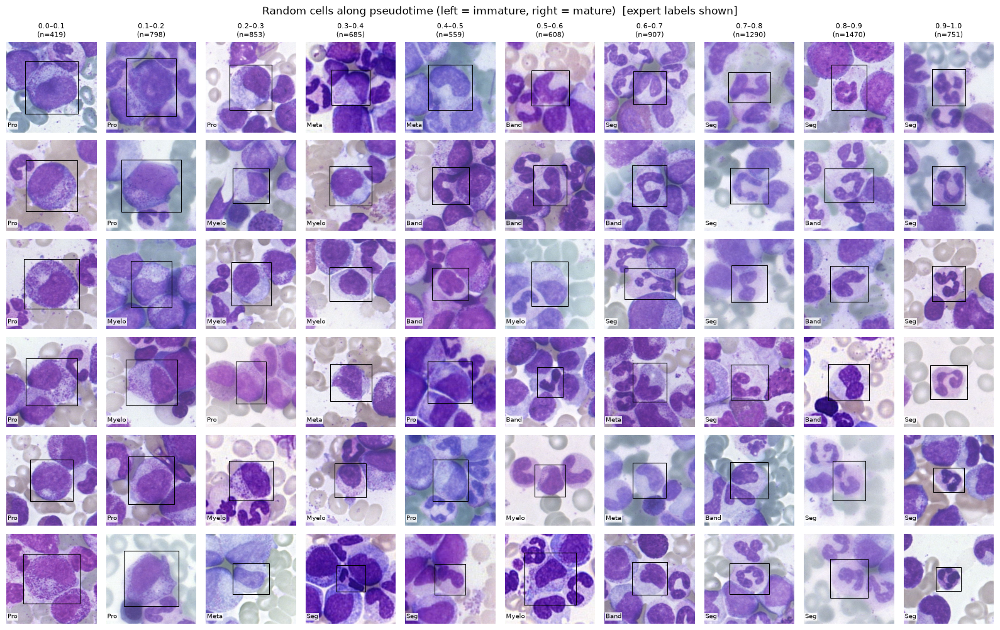

In [19]:
from PIL import Image

SHOW_LABELS = True          # first look blinded; then set True and rerun
N_BINS, N_PER_BIN = 10, 6
rng_gallery = np.random.default_rng(1)
edges = np.linspace(0, 1, N_BINS + 1)

fig, axes = plt.subplots(N_PER_BIN, N_BINS, figsize=(N_BINS * 1.6, N_PER_BIN * 1.7))
for b in range(N_BINS):
    in_bin = np.where((pseudotime >= edges[b]) & (pseudotime <= edges[b + 1]))[0]
    chosen = rng_gallery.choice(in_bin, size=min(N_PER_BIN, len(in_bin)), replace=False)
    axes[0, b].set_title(f"{edges[b]:.1f}–{edges[b + 1]:.1f}\n(n={len(in_bin)})", fontsize=8)
    for r in range(N_PER_BIN):
        ax = axes[r, b]
        ax.axis("off")
        if r < len(chosen):
            row = chosen[r]
            ax.imshow(Image.open(cells.loc[row, "image_path"]))
            c = cells.loc[row]
            scale = 320 / c["native_crop_px"]          # 1 for standard crops, 320/183 for low-res
            x0 = (c["bbox_x_min"] - c["crop_x"]) * scale
            y0 = (c["bbox_y_min"] - c["crop_y"]) * scale
            ax.add_patch(plt.Rectangle(
                (x0, y0), c["bbox_width"] * scale, c["bbox_height"] * scale,
                fill=False, edgecolor="black", lw=0.8,
            ))

            if SHOW_LABELS:
                ax.text(4, 300, short[stage[row] - 1], fontsize=7, color="black",
                        bbox=dict(facecolor="white", alpha=0.8, pad=1, edgecolor="none"))

fig.suptitle("Random cells along pseudotime (left = immature, right = mature)"
             + ("  [expert labels shown]" if SHOW_LABELS else "  [labels hidden]"))
plt.tight_layout()
plt.show()


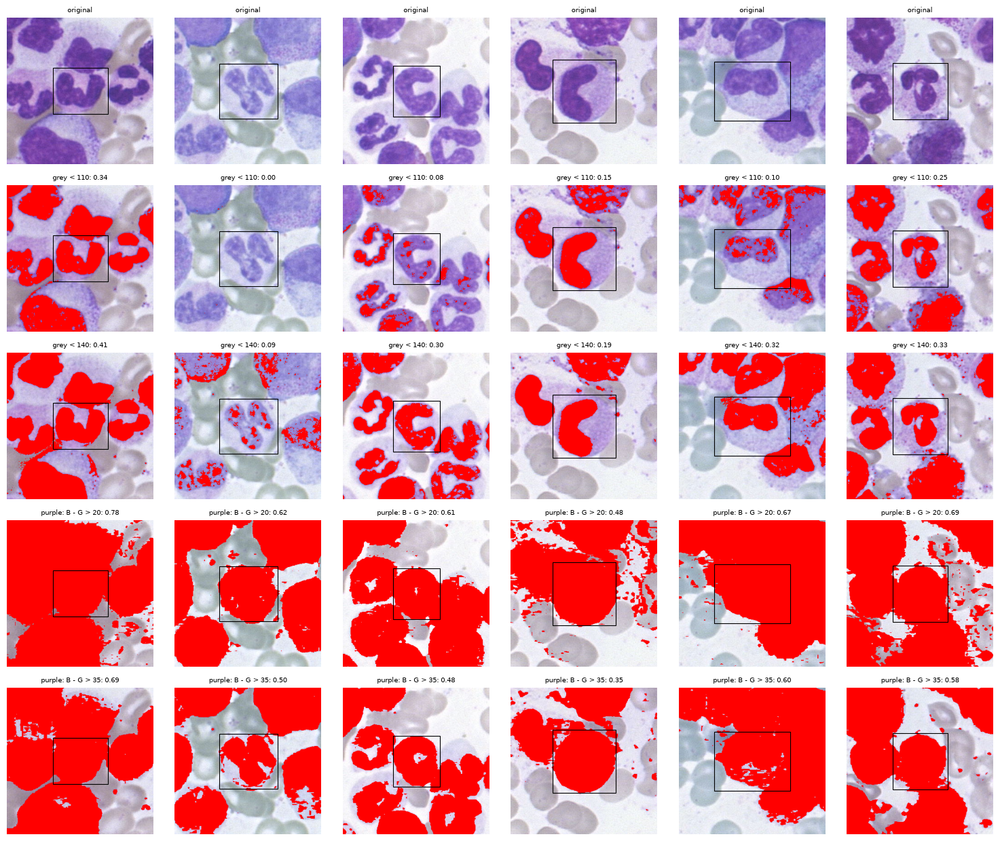

In [21]:
candidates = {
    "grey < 110": lambda rgb, grey: grey < 110,
    "grey < 140": lambda rgb, grey: grey < 140,
    "purple: B - G > 20": lambda rgb, grey: (rgb[..., 2].astype(int) - rgb[..., 1].astype(int)) > 20,
    "purple: B - G > 35": lambda rgb, grey: (rgb[..., 2].astype(int) - rgb[..., 1].astype(int)) > 35,
}

n_rows = 1 + len(candidates)
fig, axes = plt.subplots(n_rows, 6, figsize=(15, 2.5 * n_rows))
for col, row in enumerate(check_rows):
    c = cells.loc[row]
    rgb = np.asarray(Image.open(c["image_path"]).convert("RGB"))
    grey = np.asarray(Image.open(c["image_path"]).convert("L"))
    x0, y0, x1, y1 = box_in_crop(c)

    panels = [("original", rgb)]
    for name, rule in candidates.items():
        mask = rule(rgb, grey)
        overlay = rgb.copy()
        overlay[mask] = [255, 0, 0]
        panels.append((f"{name}: {mask.mean():.2f}", overlay))

    for r, (title, img) in enumerate(panels):
        ax = axes[r, col]
        ax.imshow(img)
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="black", lw=0.8))
        ax.set_title(title, fontsize=7)
        ax.axis("off")

plt.tight_layout()
plt.show()


In [22]:
import time

PURPLE_THRESHOLD = 35   # chosen in H1a

def crop_features(c):
    rgb = np.asarray(Image.open(c["image_path"]).convert("RGB"))
    grey = np.asarray(Image.open(c["image_path"]).convert("L")).astype(float)
    purple = (rgb[..., 2].astype(int) - rgb[..., 1].astype(int)) > PURPLE_THRESHOLD

    x0, y0, x1, y1 = box_in_crop(c)
    inside = np.zeros(purple.shape, dtype=bool)
    inside[y0:y1, x0:x1] = True

    return {
        "crowding_outside": purple[~inside].mean(),
        "cell_fill_inside": purple[inside].mean(),
        "stain_darkness": 255 - grey[purple].mean() if purple.any() else np.nan,
        "crop_brightness": grey.mean(),
    }

start = time.time()
rows = []
for i, c in cells.iterrows():
    rows.append(crop_features(c))
    if (i + 1) % 2000 == 0:
        print(f"{i + 1} / {len(cells)}  {time.time() - start:.0f} s")

crop_feat = pd.DataFrame(rows)
crop_feat.insert(0, "embedding_row", cells["embedding_row"].to_numpy())
crop_feat.to_csv(EMB_DIR / "crop_features_purple35.csv", index=False)
print(f"Done in {time.time() - start:.0f} s; saved crop_features_purple35.csv")

feature_cols = ["crowding_outside", "cell_fill_inside", "stain_darkness", "crop_brightness"]
print("\nMissing values:", crop_feat[feature_cols].isna().sum().to_dict())
print(crop_feat[feature_cols].describe().round(3).to_string())

print("\nPatient R² (how slide-level each measure is):")
for col in feature_cols:
    print(f"  {col:18s} {r2_by_group(crop_feat[col].to_numpy(), cells['patient_id']):.3f}")


2000 / 8340  11 s
4000 / 8340  22 s
6000 / 8340  33 s
8000 / 8340  45 s
Done in 47 s; saved crop_features_purple35.csv

Missing values: {'crowding_outside': 0, 'cell_fill_inside': 0, 'stain_darkness': 0, 'crop_brightness': 0}
       crowding_outside  cell_fill_inside  stain_darkness  crop_brightness
count          8340.000          8340.000        8340.000         8340.000
mean              0.549             0.829         124.227          158.916
std               0.209             0.116          14.317           20.213
min               0.000             0.338          84.408           94.985
25%               0.403             0.761         114.099          145.056
50%               0.551             0.846         123.462          159.079
75%               0.697             0.918         133.425          172.545
max               1.000             1.000         171.477          233.586

Patient R² (how slide-level each measure is):
  crowding_outside   0.313
  cell_fill_inside   0.24

feature  cell_fill_inside  crowding_outside  stain_darkness
stage                                                      
Pro                -0.050            -0.005          -0.174
Myelo              -0.268            -0.155          -0.216
Meta               -0.327            -0.327          -0.354
Band               -0.490            -0.499          -0.412
Seg                -0.603            -0.579          -0.435

(full table, raw and within-patient)
stage          feature    n  rho_raw  rho_within_patient
  Pro crowding_outside 1510    0.080              -0.005
  Pro   stain_darkness 1510   -0.212              -0.174
  Pro cell_fill_inside 1510    0.047              -0.050
Myelo crowding_outside 1460   -0.151              -0.155
Myelo   stain_darkness 1460   -0.225              -0.216
Myelo cell_fill_inside 1460   -0.252              -0.268
 Meta crowding_outside  926   -0.347              -0.327
 Meta   stain_darkness  926   -0.306              -0.354
 Meta cell_fill_inside  926  

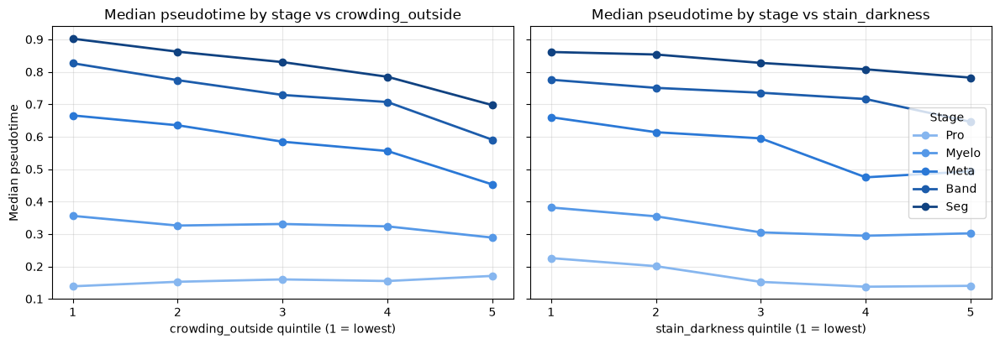

In [23]:
crop_feat = pd.read_csv(EMB_DIR / "crop_features_purple35.csv")
assert (crop_feat["embedding_row"] == cells["embedding_row"]).all()

# Discordance: distance from the cell's stage median along pseudotime
stage_median = pd.Series(pseudotime).groupby(stage).median()
discordance = pseudotime - stage_median.loc[stage].to_numpy()

# Centre within patient x stage: compares cells from the same slide and stage only
groups = [cells["patient_id"].to_numpy(), stage]
def centre_within(x):
    return x - pd.Series(x).groupby(groups).transform("mean").to_numpy()

disc_c = centre_within(discordance)

features = ["crowding_outside", "stain_darkness", "cell_fill_inside"]
rows = []
for s in range(1, 6):
    m = stage == s
    for f in features:
        x = crop_feat[f].to_numpy()
        rows.append({
            "stage": short[s - 1],
            "feature": f,
            "n": int(m.sum()),
            "rho_raw": spearmanr(x[m], discordance[m]).statistic,
            "rho_within_patient": spearmanr(centre_within(x)[m], disc_c[m]).statistic,
        })
h2 = pd.DataFrame(rows)
print(h2.pivot(index="stage", columns="feature", values="rho_within_patient")
        .reindex(short).round(3).to_string())
print("\n(full table, raw and within-patient)")
print(h2.round(3).to_string(index=False))

# Picture: median pseudotime per stage across crowding / darkness quintiles
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
stage_colors = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
for ax, f in zip(axes, ["crowding_outside", "stain_darkness"]):
    q = pd.qcut(crop_feat[f], 5, labels=False).to_numpy()
    for s in range(1, 6):
        meds = [np.median(pseudotime[(stage == s) & (q == b)]) for b in range(5)]
        ax.plot(range(1, 6), meds, marker="o", color=stage_colors[s - 1], lw=2, label=short[s - 1])
    ax.set_xticks(range(1, 6))
    ax.set_xlabel(f"{f} quintile (1 = lowest)")
    ax.set_title(f"Median pseudotime by stage vs {f}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Median pseudotime")
axes[1].legend(title="Stage", loc="center right")
plt.tight_layout()
plt.show()


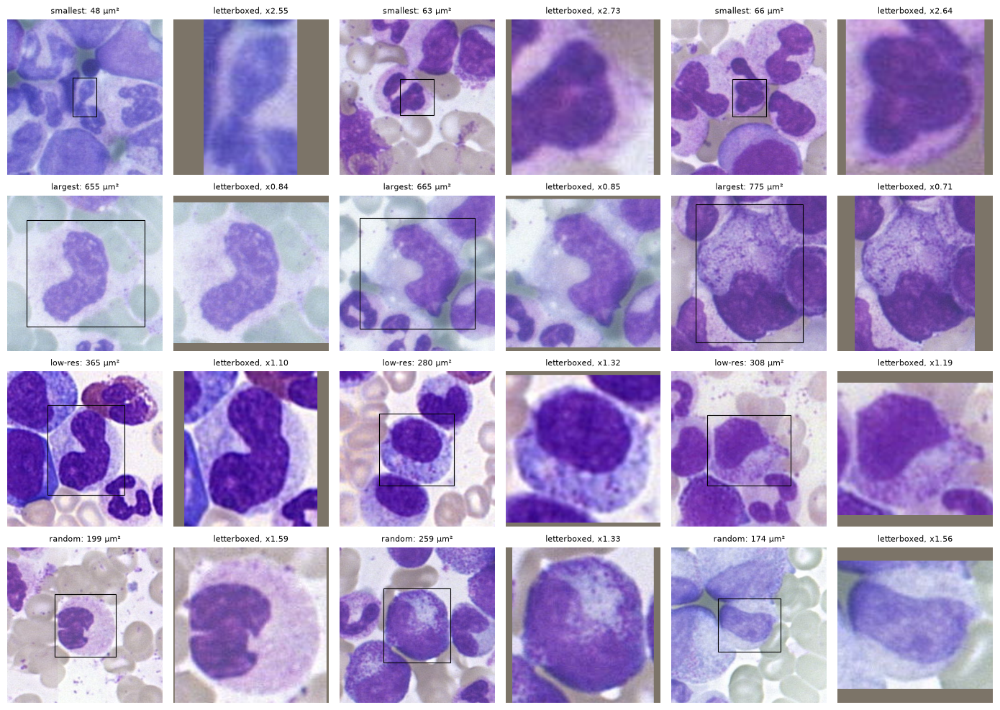

In [28]:
PAD_COLOR = (124, 116, 104)   # ImageNet mean x 255 -> exactly 0 after normalization
MARGIN = 0.05                # extra 10% of box width/height on each side
OUT_SIZE = 224

def tight_letterbox(c, margin=MARGIN, size=OUT_SIZE, pad_color=PAD_COLOR):
    """Crop the annotated box (+margin) from the stored 320x320 crop, scale so the
    longest side = size, pad the short side. Returns (image, scale_factor)."""
    img = Image.open(c["image_path"]).convert("RGB")
    s = 320 / c["native_crop_px"]                       # box coords -> stored-crop pixels
    x0 = (c["bbox_x_min"] - c["crop_x"]) * s
    y0 = (c["bbox_y_min"] - c["crop_y"]) * s
    x1 = (c["bbox_x_max"] - c["crop_x"]) * s
    y1 = (c["bbox_y_max"] - c["crop_y"]) * s
    w, h = x1 - x0, y1 - y0
    x0, x1 = max(0, x0 - margin * w), min(320, x1 + margin * w)
    y0, y1 = max(0, y0 - margin * h), min(320, y1 + margin * h)

    cell = img.crop((round(x0), round(y0), round(x1), round(y1)))
    f = size / max(cell.size)                            # one rule: longest side -> 224
    new_w, new_h = max(1, round(cell.width * f)), max(1, round(cell.height * f))
    cell = cell.resize((new_w, new_h), Image.Resampling.BICUBIC)

    canvas = Image.new("RGB", (size, size), pad_color)
    canvas.paste(cell, ((size - new_w) // 2, (size - new_h) // 2))
    return canvas, f

# Pick preview cells: smallest, largest, low-res, random
area = (cells["bbox_width"] * cells["bbox_height"] * cells["pixel_spacing_um"] ** 2).to_numpy()
order = np.argsort(area)
rng_prev = np.random.default_rng(3)
preview = (
    list(order[:3]) + list(order[-3:])
    + list(rng_prev.choice(np.where(cells["resized_from_native"])[0], 3, replace=False))
    + list(rng_prev.choice(len(cells), 3, replace=False))
)
groups_txt = ["smallest"] * 3 + ["largest"] * 3 + ["low-res"] * 3 + ["random"] * 3

fig, axes = plt.subplots(4, 6, figsize=(14, 10))
for k, (row, g) in enumerate(zip(preview, groups_txt)):
    c = cells.loc[row]
    orig = Image.open(c["image_path"]).convert("RGB")
    tight, f = tight_letterbox(c)
    ax_o, ax_t = axes[(k // 3), (k % 3) * 2], axes[(k // 3), (k % 3) * 2 + 1]
    x0, y0, x1, y1 = box_in_crop(c)
    ax_o.imshow(orig)
    ax_o.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="black", lw=0.8))
    ax_o.set_title(f"{g}: {area[row]:.0f} µm²", fontsize=8)
    ax_t.imshow(tight)
    ax_t.set_title(f"letterboxed, x{f:.2f}", fontsize=8)
    for ax in (ax_o, ax_t):
        ax.axis("off")
plt.tight_layout()
plt.show()


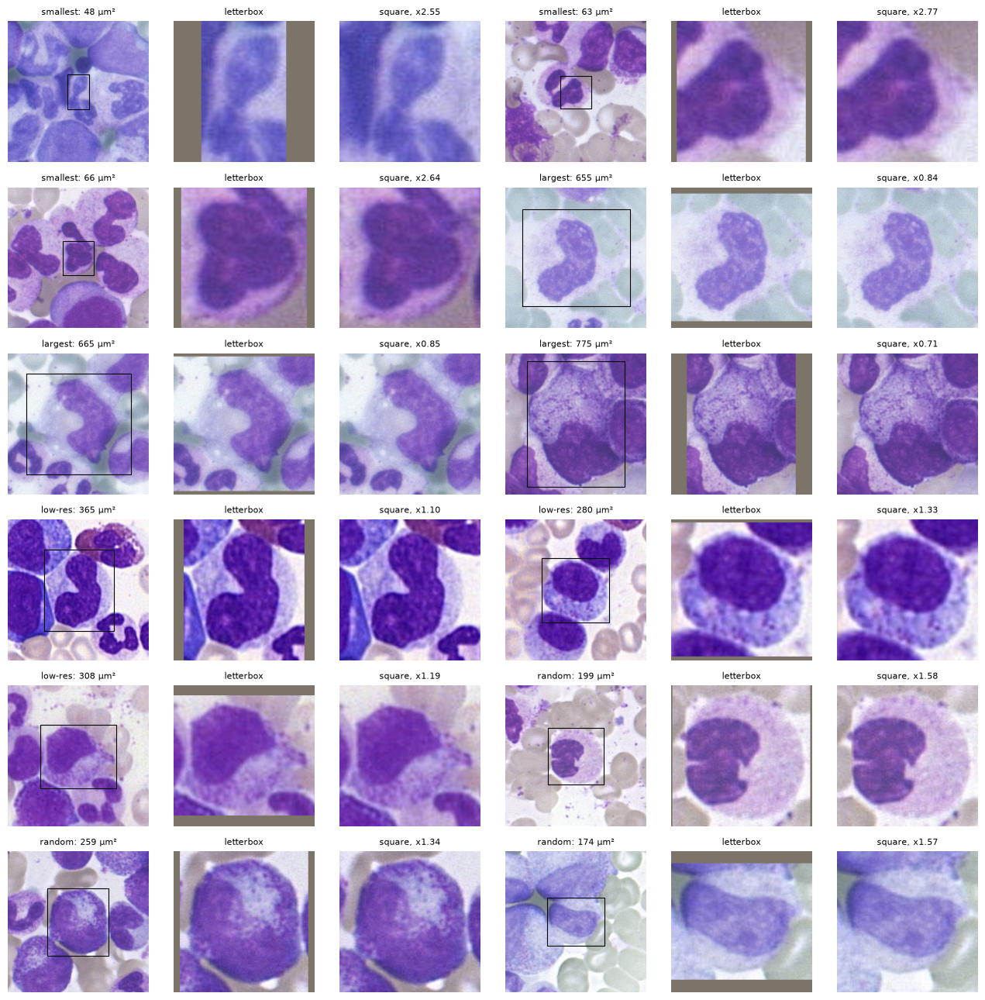

In [29]:
def tight_square(c, margin=MARGIN, size=OUT_SIZE, pad_color=PAD_COLOR):
    """Square region centred on the box, side = longest box side x (1 + 2*margin),
    resized to size x size. Any area outside the stored crop is filled with pad_color.
    Returns (image, scale_factor)."""
    img = Image.open(c["image_path"]).convert("RGB")
    s = 320 / c["native_crop_px"]
    x0 = (c["bbox_x_min"] - c["crop_x"]) * s
    y0 = (c["bbox_y_min"] - c["crop_y"]) * s
    x1 = (c["bbox_x_max"] - c["crop_x"]) * s
    y1 = (c["bbox_y_max"] - c["crop_y"]) * s

    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    side = round(max(x1 - x0, y1 - y0) * (1 + 2 * margin))
    left, top = round(cx - side / 2), round(cy - side / 2)

    canvas = Image.new("RGB", (side, side), pad_color)
    canvas.paste(img, (-left, -top))       # stored crop placed so (left, top) lands at (0, 0)
    f = size / side
    return canvas.resize((size, size), Image.Resampling.BICUBIC), f

fig, axes = plt.subplots(6, 6, figsize=(13, 13))
for k, (row, g) in enumerate(zip(preview, groups_txt)):
    c = cells.loc[row]
    r, col0 = k // 2, (k % 2) * 3
    orig = Image.open(c["image_path"]).convert("RGB")
    letter, _ = tight_letterbox(c)
    square, f = tight_square(c)
    x0, y0, x1, y1 = box_in_crop(c)

    axes[r, col0].imshow(orig)
    axes[r, col0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="black", lw=0.8))
    axes[r, col0].set_title(f"{g}: {area[row]:.0f} µm²", fontsize=8)
    axes[r, col0 + 1].imshow(letter)
    axes[r, col0 + 1].set_title("letterbox", fontsize=8)
    axes[r, col0 + 2].imshow(square)
    axes[r, col0 + 2].set_title(f"square, x{f:.2f}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()


In [30]:
from scipy import ndimage

rng_fit = np.random.default_rng(4)
sample = rng_fit.choice(len(cells), size=500, replace=False)

fit_rows = []
for row in sample:
    c = cells.loc[row]
    rgb = np.asarray(Image.open(c["image_path"]).convert("RGB"))
    purple = (rgb[..., 2].astype(int) - rgb[..., 1].astype(int)) > PURPLE_THRESHOLD
    purple = ndimage.binary_opening(purple, iterations=2)       # remove small specks
    labels_img, _ = ndimage.label(purple)                      # number each connected blob

    x0, y0, x1, y1 = box_in_crop(c)
    bx, by = (x0 + x1) / 2, (y0 + y1) / 2
    blob_id = labels_img[int(by), int(bx)]
    if blob_id == 0:
        fit_rows.append({"row": row, "cell_at_centre": False})
        continue

    blob = labels_img == blob_id
    ys, xs = np.nonzero(blob)
    inside = np.zeros(blob.shape, dtype=bool)
    inside[y0:y1, x0:x1] = True
    um_per_px = c["pixel_spacing_um"] * c["native_crop_px"] / 320

    fit_rows.append({
        "row": row,
        "cell_at_centre": True,
        "touches_crop_edge": xs.min() == 0 or ys.min() == 0 or xs.max() == 319 or ys.max() == 319,
        "blob_to_box_area": blob.sum() / ((x1 - x0) * (y1 - y0)),
        "frac_cell_outside_box": (blob & ~inside).sum() / blob.sum(),
        "centre_offset_um": np.hypot(xs.mean() - bx, ys.mean() - by) * um_per_px,
        "lowres": bool(c["resized_from_native"]),
    })

fit = pd.DataFrame(fit_rows)
print("Purple object at box centre:", fit["cell_at_centre"].sum(), "/", len(fit))

ok = fit[fit["cell_at_centre"]]
clean = ok[~ok["touches_crop_edge"] & (ok["blob_to_box_area"] < 1.5)]   # likely a single cell
print("Clean single-cell cases:", len(clean), "/", len(ok))

cols = ["frac_cell_outside_box", "centre_offset_um", "blob_to_box_area"]
print("\nClean cases:")
print(clean[cols].describe(percentiles=[0.1, 0.5, 0.9]).round(3).to_string())
print("\nShare of clean cases with >10% of the cell outside the box:",
      round((clean["frac_cell_outside_box"] > 0.10).mean(), 3))
print("\nLow-res vs standard (clean cases, medians):")
print(clean.groupby("lowres")[cols].median().round(3).to_string())


Purple object at box centre: 476 / 500
Clean single-cell cases: 46 / 476

Clean cases:
       frac_cell_outside_box  centre_offset_um  blob_to_box_area
count                 46.000            46.000            46.000
mean                   0.102             1.454             0.795
std                    0.152             1.728             0.243
min                    0.000             0.078             0.320
10%                    0.000             0.104             0.545
50%                    0.003             0.511             0.715
90%                    0.350             4.337             1.193
max                    0.473             6.018             1.337

Share of clean cases with >10% of the cell outside the box: 0.304

Low-res vs standard (clean cases, medians):
        frac_cell_outside_box  centre_offset_um  blob_to_box_area
lowres                                                           
False                   0.003             0.442             0.728
True              

Longest box side (µm):
count    8340.0
mean       15.8
std         2.6
min         8.2
1%         10.7
5%         12.1
25%        14.0
50%        15.4
75%        17.3
95%        20.6
99%        23.3
max        31.7
  boxes with longest side < 8 µm: 0
  boxes with longest side < 10 µm: 29
  boxes with longest side < 12 µm: 383
  boxes with longest side > 25 µm: 22
  boxes with longest side > 30 µm: 1

Median longest side by stage (µm):
label
promyelocyte                  18.2
neutrophilic_myelocyte        16.4
neutrophilic_metamyelocyte    15.1
neutrophilic_band             14.8
segmented_neutrophil          14.5


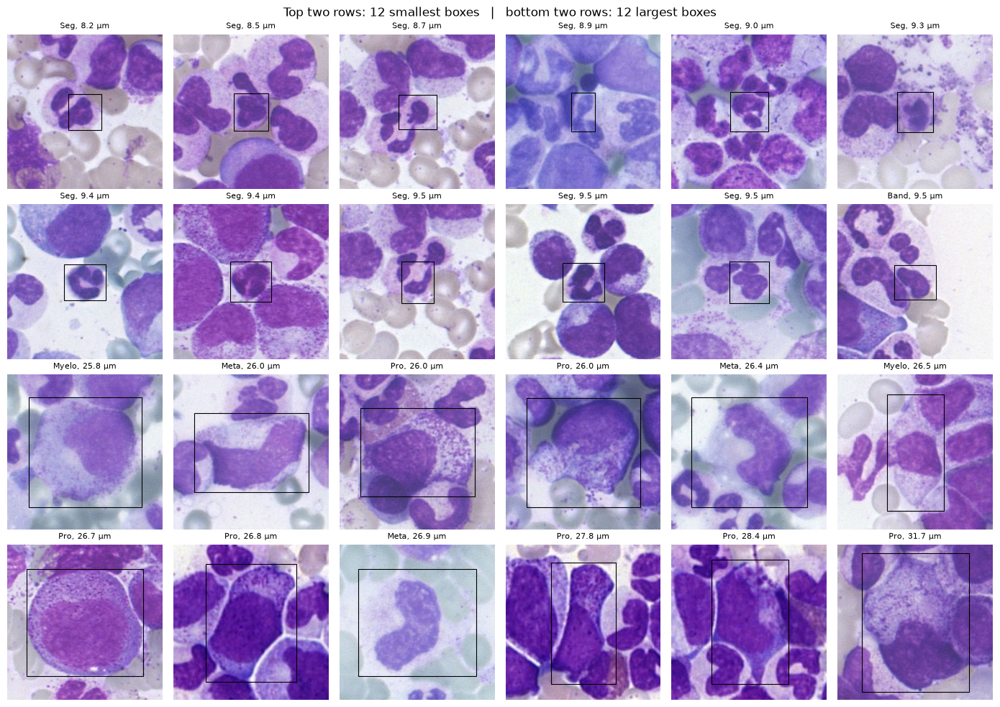

In [31]:
side_um = (np.maximum(cells["bbox_width"], cells["bbox_height"]) * cells["pixel_spacing_um"]).to_numpy()

print("Longest box side (µm):")
print(pd.Series(side_um).describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1).to_string())
for t in [8, 10, 12]:
    print(f"  boxes with longest side < {t} µm: {(side_um < t).sum()}")
for t in [25, 30]:
    print(f"  boxes with longest side > {t} µm: {(side_um > t).sum()}")

print("\nMedian longest side by stage (µm):")
print(pd.Series(side_um).groupby(cells["label"]).median().reindex(TARGET_STAGES).round(1).to_string())

# Gallery: 12 smallest and 12 largest boxes, with labels
order_side = np.argsort(side_um)
show = list(order_side[:12]) + list(order_side[-12:])
fig, axes = plt.subplots(4, 6, figsize=(14, 10))
for ax, row in zip(axes.ravel(), show):
    c = cells.loc[row]
    x0, y0, x1, y1 = box_in_crop(c)
    ax.imshow(Image.open(c["image_path"]).convert("RGB"))
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="black", lw=0.8))
    ax.set_title(f"{short[stage[row] - 1]}, {side_um[row]:.1f} µm", fontsize=8)
    ax.axis("off")
fig.suptitle("Top two rows: 12 smallest boxes   |   bottom two rows: 12 largest boxes")
plt.tight_layout()
plt.show()


## I. Tight crops around the annotated cell

**Amendment 2026-10-05 (after H2; an improvement study, not part of the pre-specified analysis).**
H2 showed that, within a stage, cells in crowded or darkly stained fields were placed earlier along the pseudotime
(within-patient ρ with crowding down to −0.58 for segmented neutrophils), i.e. part of the original embedding
describes the *surroundings* of the 35.5 µm crop. Here we re-embed tight crops around each annotated cell and apply
**exactly the same checks** (S1–S4, V1–V3, the size amendment and the H2 context test) to five versions:

| Version | What the model sees |
|---|---|
| `original` | fixed 35.5 µm field (stored 320 px crop → 224 px), neighbours included |
| `square_m05` / `square_m10` | square around the box, side = longest box side × 1.10 / × 1.20, resized to 224 |
| `letterbox_m05` / `letterbox_m10` | box + 5% / 10% per side, longest side → 224, short side padded with the ImageNet mean colour |

Notes: crops are made in memory from the stored 320×320 PNGs (nothing on disk is changed); absolute cell size is
removed from the image by design (every cell fills the frame); padding/overhang uses the ImageNet mean colour, which
becomes exactly 0 after normalization. The variant to carry forward is chosen on design grounds, not by best label
agreement (see the summary at the end of this section).

In [ ]:
# I.1 Setup (self-contained: loads everything it needs from disk)
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import spearmanr, rankdata
from scipy.sparse import csr_matrix, diags
from scipy.sparse.linalg import eigsh
from scipy.sparse.csgraph import connected_components
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, kneighbors_graph

EMB_ROOT = Path("../data/embeddings")
TARGET_STAGES = [
    "promyelocyte",
    "neutrophilic_myelocyte",
    "neutrophilic_metamyelocyte",
    "neutrophilic_band",
    "segmented_neutrophil",
]
short = ["Pro", "Myelo", "Meta", "Band", "Seg"]
STAGE_COLORS = ["#440154", "#3b528b", "#21918c", "#5ec962", "#fde725"]   # viridis, as in earlier plots

cells = pd.read_csv(EMB_ROOT / "dinobloom_b" / "cells.csv", dtype={"patient_id": str})
crop_feat = pd.read_csv(EMB_ROOT / "dinobloom_b" / "crop_features_purple35.csv")
assert (crop_feat["embedding_row"] == cells["embedding_row"]).all()

N = len(cells)
pid = cells["patient_id"].to_numpy()
lowres = cells["resized_from_native"].to_numpy()
stage = cells["label"].map({s: i for i, s in enumerate(TARGET_STAGES, start=1)}).to_numpy()
area = (cells["bbox_width"] * cells["bbox_height"] * cells["pixel_spacing_um"] ** 2).to_numpy()
box_side = (np.maximum(cells["bbox_width"], cells["bbox_height"]) * cells["pixel_spacing_um"]).to_numpy()

PAD_COLOR = (124, 116, 104)   # ImageNet mean x 255 -> exactly 0 after normalization
OUT_SIZE = 224
VERSIONS = {
    "original": None,
    "square_m05": ("square", 0.05),
    "square_m10": ("square", 0.10),
    "letterbox_m05": ("letterbox", 0.05),
    "letterbox_m10": ("letterbox", 0.10),
}
METHOD_LABEL = {
    "original": "ORIGINAL: fixed 35.5 µm field, neighbours included",
    "square_m05": "SQUARE 5%: square around box, side = longest side × 1.10",
    "square_m10": "SQUARE 10%: square around box, side = longest side × 1.20",
    "letterbox_m05": "LETTERBOX 5%: box + 5%/side, padded to square",
    "letterbox_m10": "LETTERBOX 10%: box + 10%/side, padded to square",
}
print("Cells:", N, "| patients:", cells["patient_id"].nunique())

In [ ]:
# I.2 Crop functions (work on an already-opened stored 320x320 crop) + example of each method
def box_in_stored_crop(c):
    """Annotated box in stored-crop pixel coordinates (float x0, y0, x1, y1)."""
    s = 320 / c["native_crop_px"]
    return ((c["bbox_x_min"] - c["crop_x"]) * s, (c["bbox_y_min"] - c["crop_y"]) * s,
            (c["bbox_x_max"] - c["crop_x"]) * s, (c["bbox_y_max"] - c["crop_y"]) * s)


def crop_square(img, c, margin):
    """Square centred on the box, side = longest box side x (1 + 2*margin), resized to 224.
    Any part outside the stored crop is filled with PAD_COLOR. Returns (image, scale_factor)."""
    x0, y0, x1, y1 = box_in_stored_crop(c)
    side = round(max(x1 - x0, y1 - y0) * (1 + 2 * margin))
    left, top = round((x0 + x1) / 2 - side / 2), round((y0 + y1) / 2 - side / 2)
    canvas = Image.new("RGB", (side, side), PAD_COLOR)
    canvas.paste(img, (-left, -top))          # (left, top) of the square lands at (0, 0)
    return canvas.resize((OUT_SIZE, OUT_SIZE), Image.Resampling.BICUBIC), OUT_SIZE / side


def crop_letterbox(img, c, margin):
    """Box + margin, longest side scaled to 224, short side padded with PAD_COLOR.
    Returns (image, scale_factor)."""
    x0, y0, x1, y1 = box_in_stored_crop(c)
    w, h = x1 - x0, y1 - y0
    x0, x1 = max(0, x0 - margin * w), min(320, x1 + margin * w)
    y0, y1 = max(0, y0 - margin * h), min(320, y1 + margin * h)
    cell = img.crop((round(x0), round(y0), round(x1), round(y1)))
    f = OUT_SIZE / max(cell.size)
    new_w, new_h = max(1, round(cell.width * f)), max(1, round(cell.height * f))
    canvas = Image.new("RGB", (OUT_SIZE, OUT_SIZE), PAD_COLOR)
    canvas.paste(cell.resize((new_w, new_h), Image.Resampling.BICUBIC),
                 ((OUT_SIZE - new_w) // 2, (OUT_SIZE - new_h) // 2))
    return canvas, f


CROPPERS = {"square": crop_square, "letterbox": crop_letterbox}

# Example: one band neutrophil in a crowded field, as the model receives it under each method
asp = (cells["bbox_width"] / cells["bbox_height"]).to_numpy()
candidates = np.where((stage == 4) & ~lowres
                      & (crop_feat["crowding_outside"].between(0.6, 0.8)).to_numpy()
                      & (np.abs(asp - 1) > 0.15) & (np.abs(asp - 1) < 0.35))[0]
example_row = int(np.random.default_rng(5).choice(candidates))
ex = cells.loc[example_row]
ex_img = Image.open(ex["image_path"]).convert("RGB")

fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, (name, spec) in zip(axes, VERSIONS.items()):
    if spec is None:
        shown = ex_img.resize((OUT_SIZE, OUT_SIZE), Image.Resampling.BILINEAR)
    else:
        shown, _ = CROPPERS[spec[0]](ex_img, ex, spec[1])
    ax.imshow(shown)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
fig.suptitle(f"Model input under each cropping method (example cell {ex['cell_id']})")
plt.tight_layout()
plt.show()

In [ ]:
# I.3 Embeddings: load each tight-crop version if it is already on disk, otherwise compute it.
#     (They were computed on 2026-10-05; re-running this cell only loads them.)
def load_dinobloom():
    import torch
    import torch.nn as nn
    hub_dir = Path.home() / ".cache/torch/hub/facebookresearch_dinov2_main"
    m = torch.hub.load(str(hub_dir), "dinov2_vitb14", source="local", pretrained=False)
    teacher = torch.load(Path("../models/DinoBloom-B.pth"), map_location="cpu", weights_only=True)["teacher"]
    weights = {k.replace("backbone.", ""): v for k, v in teacher.items()
               if "dino_head" not in k and "ibot_head" not in k}
    m.pos_embed = nn.Parameter(torch.zeros(1, 257, 768))
    print(m.load_state_dict(weights, strict=True))
    m.eval()
    for p in m.parameters():
        p.requires_grad_(False)
    dev = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
    return m.to(dev), dev


def embed_version(name, kind, margin, model, device, batch_size=64):
    import torch
    from torchvision import transforms
    norm = transforms.Compose([transforms.ToTensor(),
                               transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
    cls_list, patch_list, scale = [], [], np.zeros(N)
    start = time.time()
    with torch.no_grad():
        for i in range(0, N, batch_size):
            tensors = []
            for j in range(i, min(i + batch_size, N)):
                c = cells.loc[j]
                img, scale[j] = CROPPERS[kind](Image.open(c["image_path"]).convert("RGB"), c, margin)
                tensors.append(norm(img))
            out = model.forward_features(torch.stack(tensors).to(device))
            cls_list.append(out["x_norm_clstoken"].cpu())
            patch_list.append(out["x_norm_patchtokens"].mean(dim=1).cpu())
    folder = EMB_ROOT / f"dinobloom_b_{name}"
    folder.mkdir(exist_ok=False)
    np.save(folder / "emb_cls.npy", torch.cat(cls_list).numpy())
    np.save(folder / "emb_patch_mean.npy", torch.cat(patch_list).numpy())
    pd.DataFrame({"embedding_row": cells["embedding_row"], "cell_id": cells["cell_id"],
                  "scale_factor": scale}).to_csv(folder / "crop_scale.csv", index=False)
    print(f"{name}: embedded in {time.time() - start:.0f} s")


EMBEDDINGS, SCALE = {}, {}
model = None
for name, spec in VERSIONS.items():
    folder = EMB_ROOT / ("dinobloom_b" if spec is None else f"dinobloom_b_{name}")
    if not (folder / "emb_cls.npy").exists():
        if model is None:
            model, device = load_dinobloom()
        embed_version(name, spec[0], spec[1], model, device)
    EMBEDDINGS[name] = np.load(folder / "emb_cls.npy")
    SCALE[name] = (pd.read_csv(folder / "crop_scale.csv")["scale_factor"].to_numpy()
                   if spec is not None else np.full(N, OUT_SIZE / 320))
    X = EMBEDDINGS[name]
    print(f"{name:15s} {X.shape}  finite: {np.isfinite(X).all()}  distinct rows: {len(np.unique(X, axis=0))}")

In [ ]:
# I.4 One function that applies every pre-specified check to one version
def r2_by_group(values, groups):
    df = pd.DataFrame({"v": values, "g": np.asarray(groups)})
    group_means = df.groupby("g")["v"].transform("mean")
    return 1 - ((df["v"] - group_means) ** 2).sum() / ((df["v"] - df["v"].mean()) ** 2).sum()


def diffusion_map(Y, k=15, n_eig=6, seed=0):
    """Local-scaling Gaussian kernel, density normalization (alpha = 1), random-walk eigenvectors.
    Returns eigenvalues (incl. trivial), diffusion components (trivial removed), trivial eigenvector."""
    n = len(Y)
    d, nbr = NearestNeighbors(n_neighbors=k + 1).fit(Y).kneighbors(Y)
    assert (nbr[:, 0] == np.arange(n)).all()
    d, nbr = d[:, 1:], nbr[:, 1:]
    sigma = d[:, -1]
    rows_i, cols_j = np.repeat(np.arange(n), k), nbr.ravel()
    w = np.exp(-d.ravel() ** 2 / (sigma[rows_i] * sigma[cols_j]))
    W = csr_matrix((w, (rows_i, cols_j)), shape=(n, n))
    W = W.maximum(W.T)
    q = np.asarray(W.sum(axis=1)).ravel()
    W_tilde = diags(1 / q) @ W @ diags(1 / q)
    row_sum = np.asarray(W_tilde.sum(axis=1)).ravel()
    M_sym = diags(row_sum ** -0.5) @ W_tilde @ diags(row_sum ** -0.5)
    vals, vecs = eigsh(M_sym, k=n_eig, which="LA", v0=np.random.default_rng(seed).random(n))
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    psi = vecs * (row_sum ** -0.5)[:, None]
    return vals, psi[:, 1:], psi[:, 0]


patient_rows = [g.index.to_numpy() for _, g in cells.groupby("patient_id")]


def centre_within_patient_stage(x):
    return x - pd.Series(x).groupby([pid, stage]).transform("mean").to_numpy()


def analyse_version(X, scale_factor, n_perm=200):
    res, out = {}, {}
    rho = lambda a, b: spearmanr(a, b).statistic

    # --- label-free structure
    norms = np.linalg.norm(X, axis=1)
    Z = PCA(n_components=200, random_state=0).fit_transform(X / norms[:, None])
    Zk = Z[:, :50]

    nb = NearestNeighbors(n_neighbors=16).fit(Zk).kneighbors(Zk, return_distance=False)
    assert (nb[:, 0] == np.arange(N)).all()
    nb = nb[:, 1:]
    res["same_patient_nbrs"] = (pid[nb] == pid[:, None]).mean()

    union_largest, mutual_largest = [], []
    for n_pcs in [20, 50, 100]:
        for k in [10, 15, 30]:
            A = kneighbors_graph(Z[:, :n_pcs], n_neighbors=k, include_self=False)
            for rule, G in [("union", A.maximum(A.T)), ("mutual", A.minimum(A.T))]:
                _, comp = connected_components(G, directed=False)
                (union_largest if rule == "union" else mutual_largest).append(np.bincount(comp).max() / N)
    res["S1_union_min_largest"] = min(union_largest)
    res["S1_mutual_min_largest"] = min(mutual_largest)

    evals, DC, trivial = diffusion_map(Zk, k=15, n_eig=16)
    res["DC1_eigenvalue"], res["DC2_eigenvalue"] = evals[1], evals[2]
    res["S4_eigs_above_0.98"] = int((evals[1:] > 0.98).sum())
    res["S2_R2_patient_DC1"] = r2_by_group(DC[:, 0], pid)
    res["R2_patient_DC2_to_DC5"] = [round(r2_by_group(DC[:, i], pid), 2) for i in range(1, 5)]
    res["S3_R2_lowres_DC1"] = r2_by_group(DC[:, 0], lowres)
    res["S3_rho_DC1_bbox_area"] = rho(DC[:, 0], area)
    res["S3_rho_DC1_scale_factor"] = rho(DC[:, 0], scale_factor) if np.ptp(scale_factor) > 0 else np.nan

    stab = []
    for n_pcs in [20, 50, 100]:
        for k in [10, 15, 30]:
            _, d1, _ = diffusion_map(Z[:, :n_pcs], k=k)
            stab.append(abs(rho(d1[:, 0], DC[:, 0])))
    std = ~lowres
    _, d1, _ = diffusion_map(Z[std, :50], k=15)
    stab.append(abs(rho(d1[:, 0], DC[std, 0])))
    res["stability_min_abs_rho"] = min(stab)

    # --- labels enter: orientation (direction only), then validation
    dc1 = DC[:, 0] * np.sign(rho(DC[:, 0], stage))
    pt = (dc1 - dc1.min()) / (dc1.max() - dc1.min())
    medians = pd.Series(pt).groupby(stage).median()
    res["V2_rho"] = rho(dc1, stage)
    res["V2_monotonic"] = bool(medians.is_monotonic_increasing)
    res["stage_medians"] = [round(float(m), 3) for m in medians]

    within = []
    for r in patient_rows:
        within.append((rho(dc1[r], stage[r]),
                       pd.Series(dc1[r]).groupby(stage[r]).median().is_monotonic_increasing))
    within = np.array(within, dtype=float)
    res["V3_patients_rho_pos"] = int((within[:, 0] > 0).sum())
    res["V3_patients_monotonic"] = int(within[:, 1].sum())
    res["V3_median_rho"] = float(np.median(within[:, 0]))
    res["V3_min_rho"] = float(within[:, 0].min())

    cell_i, nbr_j = np.repeat(np.arange(N), 15), nb.ravel()

    def neighbour_stats(s):
        gap = np.abs(s[cell_i] - s[nbr_j])
        return (gap == 0).mean(), (gap[gap > 0] == 1).mean()

    obs_same, obs_adj = neighbour_stats(stage)
    rng = np.random.default_rng(0)

    def shuffle_within_patients(s):
        shuffled = s.copy()
        for r in patient_rows:
            shuffled[r] = rng.permutation(s[r])
        return shuffled

    null_adj = np.array([neighbour_stats(shuffle_within_patients(stage))[1] for _ in range(n_perm)])
    res.update(V1_same_stage=obs_same, V1_adjacent=obs_adj,
               V1_null_mean=null_adj.mean(), V1_null_max=null_adj.max())

    r_area, r_dc1 = rankdata(area), rankdata(dc1)
    slope, intercept = np.polyfit(r_area, r_dc1, 1)
    res["size_partial_rho"] = rho(r_dc1 - (slope * r_area + intercept), stage)

    disc_c = centre_within_patient_stage(pt - pd.Series(pt).groupby(stage).transform("median").to_numpy())
    h2 = {}
    for f, x in [("crowding", crop_feat["crowding_outside"].to_numpy()),
                 ("stain darkness", crop_feat["stain_darkness"].to_numpy()),
                 ("box size", box_side)]:
        xc = centre_within_patient_stage(x)
        h2[f] = [round(float(rho(xc[stage == s], disc_c[stage == s])), 3) for s in range(1, 6)]
    out.update(dc1=dc1, dc2=DC[:, 1], pseudotime=pt, h2=h2)
    return res, out

In [ ]:
# I.5 Run all checks on all five versions (several minutes: 50 diffusion maps + permutations)
results, details = {}, {}
for name in VERSIONS:
    t0 = time.time()
    results[name], details[name] = analyse_version(EMBEDDINGS[name], SCALE[name])
    print(f"{name:15s} done in {time.time() - t0:.0f} s")

pseudotime_original = details["original"]["pseudotime"]
for name in VERSIONS:
    results[name]["rho_vs_original_pseudotime"] = spearmanr(details[name]["pseudotime"], pseudotime_original).statistic

summary = pd.DataFrame(results)
with pd.option_context("display.width", 200, "display.max_colwidth", 40):
    print(summary.to_string())

In [ ]:
# I.6 Decision rule per version, and dependence on the surrounding field (within patient x stage)
decision = pd.DataFrame({
    name: {
        "S1 (union largest >= 0.99)": r["S1_union_min_largest"] >= 0.99,
        "S2 (patient R2 DC1 < 0.5)": r["S2_R2_patient_DC1"] < 0.5,
        "S4 (no eigenvalue cluster near 1)": r["S4_eigs_above_0.98"] <= 1,
        "V1 (adjacent > every shuffle)": r["V1_adjacent"] > r["V1_null_max"],
        "V2 (rho > 0, monotonic medians)": r["V2_rho"] > 0 and r["V2_monotonic"],
        "V3 (majority of patients rho > 0)": r["V3_patients_rho_pos"] > 23,
    }
    for name, r in results.items()
})
print(decision.to_string())
print("\nPseudotime warranted (S1, S2, S4, V1, V2 all pass):",
      {name: bool(decision[name].iloc[[0, 1, 2, 3, 4]].all()) for name in decision})

print("\nWithin-patient rho(discordance, feature), columns Pro / Myelo / Meta / Band / Seg:")
for f in ["crowding", "stain darkness", "box size"]:
    print(f"  {f}")
    for name in VERSIONS:
        print(f"    {name:15s}", details[name]["h2"][f])

In [ ]:
# I.7 DC1 vs DC2 coloured by expert stage, one panel per cropping method
order = np.random.default_rng(0).permutation(N)          # random drawing order: no stage hides another
point_colors = np.array(STAGE_COLORS)[stage - 1]

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for ax, name in zip(axes.ravel(), VERSIONS):
    ax.scatter(details[name]["dc1"][order], details[name]["dc2"][order], c=point_colors[order], s=2, lw=0, alpha=0.85)
    ax.set_xlabel("DC1 (oriented)")
    ax.set_ylabel("DC2")
    ax.set_title(f"{METHOD_LABEL[name]}\nrho(DC1, stage) = {results[name]['V2_rho']:.3f}", loc="left", fontsize=9)
ax = axes.ravel()[-1]
ax.axis("off")
for i, (label, color) in enumerate(zip(["Promyelocyte", "Myelocyte", "Metamyelocyte", "Band", "Segmented"], STAGE_COLORS)):
    ax.scatter([0.1], [0.8 - i * 0.14], s=120, color=color, edgecolor="grey", lw=0.4)
    ax.text(0.18, 0.8 - i * 0.14, label, va="center", fontsize=11)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Expert stage (colour only; not used to build the DCs)", loc="left")
plt.tight_layout()
plt.show()

In [ ]:
# I.8 Each stage highlighted: original vs letterbox 5% crop
fig, axes = plt.subplots(5, 2, figsize=(11, 15), sharex="col", sharey="col")
for j, name in enumerate(["original", "letterbox_m05"]):
    x, y = details[name]["dc1"], details[name]["dc2"]
    axes[0, j].set_title(METHOD_LABEL[name], fontsize=10)
    for s in range(1, 6):
        ax = axes[s - 1, j]
        ax.scatter(x, y, s=1, color="#d3d2cc", lw=0)
        m = stage == s
        ax.scatter(x[m], y[m], s=2.5, color=STAGE_COLORS[s - 1], lw=0, alpha=0.9)
        ax.text(0.98, 0.05, f"{short[s - 1]} (n={m.sum()})", transform=ax.transAxes, ha="right",
                bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
    axes[4, j].set_xlabel("DC1 (oriented)")
for s in range(5):
    axes[s, 0].set_ylabel("DC2")
plt.tight_layout()
plt.show()

### I. Summary (values from the 2026-10-05 run; re-running I.5–I.6 reproduces them)

**Pseudotime is warranted for all four tight crops**: S1, S2, S4, V1, V2 and V3 pass for every version.

| | original | square 5% | square 10% | letterbox 5% | letterbox 10% |
|---|---|---|---|---|---|
| V2 ρ with stage (max 0.972) | 0.844 | 0.900 | 0.899 | 0.905 | 0.904 |
| V3 median within-patient ρ | 0.859 | 0.904 | 0.901 | 0.907 | 0.905 |
| V3 lowest patient | 0.567 | 0.731 | 0.725 | 0.740 | 0.746 |
| V1 adjacent share (null ≈ 0.37) | 0.794 | 0.862 | 0.857 | 0.873 | 0.868 |
| Same-patient neighbours (chance 0.025) | 0.408 | 0.302 | 0.310 | 0.290 | 0.296 |
| DC1 / DC2 eigenvalue | 0.952 / 0.935 | 0.976 / 0.919 | 0.975 / 0.919 | 0.979 / 0.918 | 0.978 / 0.918 |
| Crowding ρ, Seg (within patient) | −0.58 | −0.35 | −0.37 | −0.29 | −0.30 |
| ρ with original pseudotime | 1 | 0.946 | 0.949 | 0.932 | 0.937 |

**Interpretation**
- Same trajectory, sharper: stage ordering, within-patient consistency and adjacent-stage mixing all improve; DC1 is now clearly the dominant axis.
- Patient structure is weaker (same-patient neighbours 41% → ~30%); the low-resolution slides remain self-clustered but do not affect DC1.
- Dependence on the surrounding field roughly halves but is **not eliminated** (possible reasons: neighbour fragments inside boxes; cells in thick smear regions genuinely look denser).
- **Open:** DC1 still correlates ≈ −0.54 with box area and ≈ +0.49 with the enlargement factor, although absolute size is no longer in the image: biology (maturation tracks size) or artefact (small cells, enlarged most, look blurrier). Box-drawing style also varies (some boxes are nucleus-only, some loose).
- **Choice:** the variants differ by ≤ ~0.005 in ρ, which we cannot resolve; choosing by best label agreement would let labels steer the method. **Letterbox 5% is carried forward as primary** on design grounds (removes the most context); square 5% is the robustness check.